<a href="https://colab.research.google.com/github/mchen5237/DTI-classification-from-drug-molecular-fingerprint-and-protein-80-20/blob/main/Drug_Target_Interaction_from_drug_molecular_fingerprint_and_protein.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Drug Target Interaction based on binding affinity from drug molecular fingerprint and protein

---
Dataset: BindingDB for Drug-Target Interaction from kaggle
https://www.kaggle.com/datasets/rajaryan2315/bindingdb-for-drug-target-interaction?resource=download

Size: 1.59GB

Features: 3

* compound_iso_smiles: Contains the SMILES representation of small molecules
* target_sequence: Contains protein sequences in FASTA format
* labels: Contains the pKd binding affinity values between compound–target pair



##Data preprocessing

In [1]:
# import libraries
!pip install rdkit                            # or !pip install deepchem if using deep learning frameworks
from rdkit import Chem                        # Reads and writes molecular structures from SMILES strings
from rdkit.Chem import AllChem                # Calculates a wide range of molecular descriptors and fingerprints
from rdkit import DataStructs
!pip install biopython
import pandas as pd
import numpy as np
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, roc_auc_score, classification_report,
    precision_score, recall_score, f1_score,
    ConfusionMatrixDisplay, roc_curve, auc
)
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import seaborn as sns

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 37.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 28.5 MB/s  0:00:00


In [2]:
# Use Runtime type: A100 GPU
# Step 1: Mount Google Drive and load the cleaned dataset into dataframe.
from google.colab import drive
drive.mount('/content/drive')
file_path = '/content/drive/MyDrive/BIO4910_4920/bindingdb_highconf_pKd_clean.csv'
df_original = pd.read_csv(file_path)

# Print the dimensions and print the first 5 rows
print(df_original.shape)
print(df_original.head(5))

# Step 2: Sample a random 20% of the dataset
# random_state=42 ensures the same rows are picked every run (reproducible)
df = df_original.sample(frac=0.2, random_state=42).reset_index(drop=False)  # keep original row index
df = df.rename(columns={'index': 'original_row_id'}).reset_index(drop=True)
print("\nSampled shape:", df.shape)
print(df.head(5))

# Step 3: Verify sampled rows match original — no manipulation
original_rows = df_original.loc[df['original_row_id']]
original_check = original_rows.reset_index(drop=True)
sample_check = df.drop(columns='original_row_id').reset_index(drop=True)

are_identical = original_check.equals(sample_check)
print("\nData integrity check passed:", are_identical)

# Step 4: Diagnose if check fails
if not are_identical:
    diff = original_check.compare(sample_check)
    print("Differences found:\n", diff)

# Step 5: drop the column permanently
df = df.drop(columns='original_row_id').reset_index(drop=True)

Mounted at /content/drive
(2081891, 3)
                                 compound_iso_smiles  \
0  O[C@@H]1[C@@H](O)[C@@H](Cc2ccccc2)N(CCCCCC(O)=...   
1  O[C@@H]1[C@@H](O)[C@@H](Cc2ccccc2)N(C\C=C\c2cn...   
2  O[C@@H]1[C@@H](O)[C@@H](Cc2ccccc2)N(CC2CC2)C(=...   
3  OCCCCCCN1[C@H](Cc2ccccc2)[C@H](O)[C@@H](O)[C@@...   
4  OCCCCCN1[C@H](Cc2ccccc2)[C@H](O)[C@@H](O)[C@@H...   

                                     target_sequence  affinity  
0  PQITLWQRPLVTIKIGGQLKEALLDTGADDTVLEEMSLPGRWKPKM...  9.619789  
1  PQITLWQRPLVTIKIGGQLKEALLDTGADDTVLEEMSLPGRWKPKM...  9.602060  
2  PQITLWQRPLVTIKIGGQLKEALLDTGADDTVLEEMSLPGRWKPKM...  9.387216  
3  PQITLWQRPLVTIKIGGQLKEALLDTGADDTVLEEMSLPGRWKPKM...  9.096910  
4  PQITLWQRPLVTIKIGGQLKEALLDTGADDTVLEEMSLPGRWKPKM...  9.004365  

Sampled shape: (416378, 4)
   original_row_id                                compound_iso_smiles  \
0           215543  COc1cc(ccc1-c1cncc2cc(ccc12)S(=O)(=O)Nc1ccncn1...   
1           579716     COc1cc(ccc1-c1cn[nH]c1)-n1ncn(Cc2cccc

In [3]:
from rdkit import RDLogger                    # suppress warnings
RDLogger.DisableLog('rdApp.*')                # ~6 for 2081891 rows

# Step 1: Validate SMILES using validate_smiles function
def validate_smiles(smi):                           # takes a SMILES string as input and returns either a valid molecule object or None
    mol = Chem.MolFromSmiles(smi, sanitize=False)   # Sanitize is False so errors can be manually handled
                                                    # Double check the sanitize=false  what it does and what happened if set to TRUE

    if mol is None:                                 # If RDKit cannot build the molecule object, the SMILES is invalid
        return None

    try:
        Chem.SanitizeMol(mol)                       # performs valence checks, aromaticity detection,ring detection, hybridization assignment
        return mol
    except:
        return None                                 # If sanitization fails, the error is returned as None instead of crashing


# Step 2: Apply validation directly to dataframe and Create Mol column
df['Mol'] = df['compound_iso_smiles'].apply(validate_smiles)          #.apply(validate_smiles) runs validate_smiles function on every SMILES

# Step 3: Create validity column
df['Valid'] = df['Mol'].notnull()

# Step 4: Print counts
print("Total SMILES:", len(df))
print("Valid SMILES:", df['Valid'].sum())
print("Invalid SMILES:", (~df['Valid']).sum())
print("Dataset size:", df.shape)

# Step 5: Drop invalid SMILES
df = df[df['Mol'].notnull()].reset_index(drop=True)
print("Remaining SMILES after dropping invalid SMILES:", len(df))

# Step 6: Print final counts and dimension
print("Valid SMILES:", df['Valid'].sum())
print("Invalid SMILES:", (~df['Valid']).sum())
print("Final dataset size:", df.shape)

Total SMILES: 416378
Valid SMILES: 416351
Invalid SMILES: 27
Dataset size: (416378, 5)
Remaining SMILES after dropping invalid SMILES: 416351
Valid SMILES: 416351
Invalid SMILES: 0
Final dataset size: (416351, 5)


In [4]:
print(df.head(5))

                                 compound_iso_smiles  \
0  COc1cc(ccc1-c1cncc2cc(ccc12)S(=O)(=O)Nc1ccncn1...   
1     COc1cc(ccc1-c1cn[nH]c1)-n1ncn(Cc2ccccc2Cl)c1=O   
2            CCCCCCOc1cc[n+](Cc2ccccc2)c2cc(Cl)ccc12   
3  Nc1nc2c(cccc2s1)-c1ccc(c(c1-c1nn[nH]n1)S(N)(=O...   
4  FC(F)(F)c1cccc(c1)-c1ccc(cc1)-c1nnc(CCCc2ccc3c...   

                                     target_sequence  affinity  \
0  MAMLPPPGPQSFVHFTKQSLALIEQRIAERKSKEPKEEKKDDDEEA...  7.397940   
1  MSRPPPTGKMPGAPETAPGDGAGASRQRKLEALIRDPRSPINVESL...  7.560667   
2  MDERLSLLRSPPPPSARHRAHPPQRPASSGGAHTLVNHGYAEPAAG...  6.081970   
3  MELPNIMHPVAKLSTALAAALMLSGCMPGEIRPTIGQQMETGDQRF...  9.552842   
4  MLGIMAWNATCKNWLAAEAALEKYYLSIFYGIEFVVGVLGNTIVVY...  6.698970   

                                                Mol  Valid  
0  <rdkit.Chem.rdchem.Mol object at 0x7c569f234350>   True  
1  <rdkit.Chem.rdchem.Mol object at 0x7c569f2343c0>   True  
2  <rdkit.Chem.rdchem.Mol object at 0x7c569f234660>   True  
3  <rdkit.Chem.rdchem.

## Drug Representations
* converts a complex molecular structure to a machine-readable data for AI driven drug discovery prediction

Common fingerprint types:
* Morgan Fingerprint
* MACCS

### Morgan Fingerprint
- representation of a molecule that encodes local atomic environments
- predicts drug interactions and efficacy
- widely used for drug target interaction, drug similarity searching, and QSAR screening


In [5]:
# 1. Define fingerprint parameters #crash System RAM here when running the entire dataset
radius = 2                                                    # how far the algorithm looks around each atom
                                                              # considers up to 2 atoms away
nBits = 2048                                                  # number of bits in the fingerprint

# 2. Generate fingerprints
df['MorganFP_bin'] = df['Mol'].apply(                         # can't have None as a molecule object
    lambda mol: AllChem.GetMorganFingerprintAsBitVect(        # lambda mol: defines a function for each molecule
        mol,                                                  # AllChem.GetMorganFingerprintAsBitVect: generate a Morgan fingerprint as a binary bit vector from a molecule
        radius=radius,
        nBits=nBits
    )
)

df['MorganFP_count'] = df['Mol'].apply(
    lambda mol: AllChem.GetHashedMorganFingerprint(           # AllChem.GetHashedMorganFingerprint: maps substructures to a sparse vector by using hashing
                                                              # records how many times a substructure appears in the molecule
        mol,
        radius=radius,
        nBits=nBits
    )
)
# 3. Convert to NumPy arrays
MorganFP_b = np.zeros((len(df), nBits), dtype=int)     # Binary Morgan FP
MorganFP_ct = np.zeros((len(df), nBits), dtype=int)    # Count Morgan FP
for i, fp in enumerate(df['MorganFP_bin']):
    DataStructs.ConvertToNumpyArray(fp, MorganFP_b[i])

for i, fp in enumerate(df['MorganFP_count']):
    for bit, count in fp.GetNonzeroElements().items():
        MorganFP_ct[i, bit] = count

# 4. Create Dataframes
fp_columns = [f'Morgan_{i}' for i in range(nBits)]

MorganFP_b_df = pd.DataFrame(MorganFP_b, columns=fp_columns)
MorganFP_ct_df = pd.DataFrame(MorganFP_ct, columns=fp_columns)

print("Binary Morgan shape:", MorganFP_b_df.shape)
print(MorganFP_b_df.head())
print("Count Morgan shape:", MorganFP_ct_df.shape)
print(MorganFP_ct_df.head())


Binary Morgan shape: (416351, 2048)
   Morgan_0  Morgan_1  Morgan_2  Morgan_3  Morgan_4  Morgan_5  Morgan_6  \
0         0         0         0         0         1         0         0   
1         0         0         0         0         0         0         0   
2         0         0         0         0         0         0         0   
3         0         0         0         0         0         0         0   
4         0         0         0         0         0         0         0   

   Morgan_7  Morgan_8  Morgan_9  ...  Morgan_2038  Morgan_2039  Morgan_2040  \
0         0         0         0  ...            0            0            0   
1         0         0         0  ...            0            0            0   
2         0         0         0  ...            0            0            0   
3         0         0         0  ...            0            0            0   
4         0         0         0  ...            0            0            0   

   Morgan_2041  Morgan_2042  Morgan_20

### MACCS
This structural key fingerprint represents the molecules based on the fixed list of chemical features such as aromatic rings and presence of a certain atom


In [6]:
# MACCS (Bitvector) (Binary only)
# Import MACCS library
from rdkit.Chem import MACCSkeys

nBits_maccs = 167 # 166 structural keys

MACCS_FP = np.zeros((len(df), nBits_maccs), dtype=np.uint8)

for i, mol in enumerate(df['Mol']):
    fp = MACCSkeys.GenMACCSKeys(mol)                        # Generate MACCS keys fingerprint
    DataStructs.ConvertToNumpyArray(fp, MACCS_FP[i])

print("MACCS shape:", MACCS_FP.shape)
print("MACCS:", MACCS_FP)

MACCS shape: (416351, 167)
MACCS: [[0 0 0 ... 1 1 0]
 [0 0 0 ... 1 1 0]
 [0 0 0 ... 1 1 0]
 ...
 [0 0 0 ... 1 1 0]
 [0 0 0 ... 1 1 0]
 [0 0 0 ... 0 1 0]]


## Protein Representation
* converts biological data into numerical vectors for machine learning
* takes sequence, structure, and chemical properties to predict how proteins interact, fold, and function for drug discovery and machine learning

Two sequence-based feature extraction methods:
* Amino Acid Composition
* Dipeptide Composition

### Amino Acid Composition
- represention that calculate the frequency of the 20 standard amino acids in the protein sequence, not the sequence order.

In [7]:
# Generate Protein Feature Vector (Amino Acid Composition) ---
from Bio.SeqUtils.ProtParam import ProteinAnalysis
def fasta_to_amino_acid_composition(sequence):
    """Calculates the amino acid composition (AAC) of a protein sequence."""
    # Check for missing or invalid values
    if pd.isna(sequence) or not isinstance(sequence, str):
        return np.zeros(20)  # return zero vector (or use None)

    sequence = sequence.strip() #sanitize input and prevent subtle bugs from messy data

    if len(sequence) == 0:
        return np.zeros(20)

    try:
        protein_analyzer = ProteinAnalysis(sequence) #requires a clean sequence without whitespaces
        aa_counts = protein_analyzer.count_amino_acids()
        return np.array(list(aa_counts.values()))
    except Exception:
        return np.zeros(20)
    # This generates a fixed-length vector (20 dimensions for 20 AAs)
    protein_analyzer = ProteinAnalysis(sequence)
    return np.array(list(protein_analyzer.count_amino_acids().values()))

df['AAC'] = df['target_sequence'].apply(fasta_to_amino_acid_composition)

print(df['AAC'])
print("Dimension:",df['AAC'].shape)
print("Number of proteins:", df['AAC'].shape[0])
print("Vector length (per protein):", len(df['AAC'].iloc[0]))

0         [109, 37, 100, 131, 129, 101, 24, 149, 134, 20...
1         [83, 20, 90, 156, 37, 46, 27, 66, 144, 149, 41...
2         [39, 12, 23, 42, 38, 46, 11, 37, 14, 49, 12, 1...
3         [41, 2, 17, 7, 9, 25, 10, 14, 9, 22, 12, 11, 1...
4         [19, 7, 8, 9, 25, 12, 6, 29, 12, 52, 9, 24, 12...
                                ...                        
416346    [23, 12, 17, 38, 13, 20, 7, 19, 18, 39, 11, 18...
416347    [43, 13, 44, 48, 35, 33, 17, 44, 38, 59, 16, 2...
416348    [14, 5, 16, 15, 12, 18, 12, 10, 18, 22, 4, 12,...
416349    [83, 59, 65, 77, 35, 101, 35, 44, 39, 138, 23,...
416350    [51, 6, 23, 9, 7, 23, 7, 10, 5, 27, 4, 6, 22, ...
Name: AAC, Length: 416351, dtype: object
Dimension: (416351,)
Number of proteins: 416351
Vector length (per protein): 20


In [8]:
# 1. Define 20 standard amino acid
amino_acids = list("ACDEFGHIKLMNPQRSTVWY")

# 2. Function to Compute Percentage Composition
def compute_aac(sequence):

    # Handle missing or invalid values
    if pd.isna(sequence) or not isinstance(sequence, str):
        return [0]*20
    # AAC Function
    sequence = sequence.upper().strip()
    length = len(sequence)

    if length == 0:
        return [0]*20

    composition = []

    for aa in amino_acids:
        count = sequence.count(aa)
        percentage = (count / length) * 100 if length > 0 else 0
        composition.append(percentage)

    return composition

# 3. Get percentage composition and apply to dataset
AAC_matrix = np.array(df['target_sequence'].apply(compute_aac).tolist())

print("AAC shape:", AAC_matrix.shape)
# Protein has different lengths so the percentage normalize the data to be comparable

# 4. Display as a pandas DataFrame for better visualization in Colab
aac_df = pd.DataFrame(AAC_matrix, columns=amino_acids)
print(aac_df.head())

AAC shape: (416351, 20)
           A         C         D          E         F         G         H  \
0   5.482897  1.861167  5.030181   6.589537  6.488934  5.080483  1.207243   
1   5.979827  1.440922  6.484150  11.239193  2.665706  3.314121  1.945245   
2   6.782609  2.086957  4.000000   7.304348  6.608696  8.000000  1.913043   
3  15.185185  0.740741  6.296296   2.592593  3.333333  9.259259  3.703704   
4   5.688623  2.095808  2.395210   2.694611  7.485030  3.592814  1.796407   

          I          K          L         M         N         P         Q  \
0  7.494970   6.740443  10.160966  3.521127  4.929577  3.923541  2.665996   
1  4.755043  10.374640  10.734870  2.953890  4.827089  3.530259  6.556196   
2  6.434783   2.434783   8.521739  2.086957  3.304348  7.130435  3.304348   
3  5.185185   3.333333   8.148148  4.444444  4.074074  5.555556  4.444444   
4  8.682635   3.592814  15.568862  2.694611  7.185629  3.592814  2.095808   

          R         S         T         V         

### Dipeptide Composition
- measures the frequency of amino acids pairs in a protein sequence
- gives partial sequence order

certain pairs can affect the binding affinities

cons: overfitting

In [9]:
# Dipeptide Composition

# 1. Define Dipeptide Composition
from itertools import product
dipeptides = [''.join(dp) for dp in product(amino_acids, repeat=2)]

# 2. Function to Compute Dipeptide Composition
def compute_dpc(sequence):
    # Handle missing or invalid values
    if pd.isna(sequence) or not isinstance(sequence, str):
        return [0]*400

    sequence = sequence.upper().strip()
    length = len(sequence)

    if length < 2:
        return [0]*400

    dpc_vector = dict.fromkeys(dipeptides, 0)

    # Count dipeptides
    for i in range(length - 1):
        pair = sequence[i:i+2]
        if pair in dpc_vector:
            dpc_vector[pair] += 1

    # Convert to frequency (fraction)
    total = length - 1
    if total > 0:
        for key in dpc_vector:
            dpc_vector[key] /= total

    return list(dpc_vector.values())# Returns a dictionary of 400 descriptors

# 3. Function to compute DPC and apply to dataset
DPC_matrix = np.array(df['target_sequence'].apply(compute_dpc).tolist())

print("DPC shape:", DPC_matrix.shape)

# 4. Process and Display dataframe
dpc_df = pd.DataFrame(DPC_matrix, columns=dipeptides)
print(dpc_df.head())

DPC shape: (416351, 400)
         AA        AC        AD        AE        AF        AG        AH  \
0  0.004529  0.000503  0.002516  0.005033  0.003020  0.002516  0.001007   
1  0.003605  0.000721  0.006489  0.009373  0.004326  0.000721  0.000000   
2  0.005226  0.001742  0.003484  0.006969  0.003484  0.008711  0.003484   
3  0.029740  0.000000  0.007435  0.000000  0.011152  0.003717  0.003717   
4  0.006006  0.000000  0.000000  0.003003  0.006006  0.000000  0.003003   

         AI        AK        AL  ...        YM        YN        YP        YQ  \
0  0.003523  0.002516  0.009562  ...  0.002013  0.000503  0.000000  0.000503   
1  0.001442  0.006489  0.006489  ...  0.002163  0.000000  0.000000  0.002163   
2  0.008711  0.000000  0.001742  ...  0.003484  0.000000  0.003484  0.003484   
3  0.003717  0.007435  0.018587  ...  0.000000  0.000000  0.003717  0.000000   
4  0.006006  0.000000  0.009009  ...  0.000000  0.003003  0.003003  0.003003   

         YR        YS        YT        YV  

## Feature matrix
Each matrix is a different way of representing drug-protein pairs as numbers.
* First part of each name (Binary Morgan / Count Morgan / MACCS) = drug fingerprint encoding
* Second part (AAC / DPC) = protein encoding via amino acid statistics
* Example for Binary Morgan and AAC: (number of samples, 2048 feature + 20)

matrix drug-protein(X) --> target/affinity-pKd(Y)
      
[conv(smiles)+protein] ----> pKd (7)
1. [morgan_b+protein-aac] -----> pKd
2. [morgan_ct+protein-aac] -----> pKd
3. [maccs+protein-acc] ----> pKd
4. [morgan_b+protein-2pep] ----> pKd
5. [morgan_ct+protein-2pep] ----> pKd
6. [maccs+protein-aac+2pep] ----> pKd
7. [morgan_b+protein-aac+2pep] ----> pKd
8. [morgan_ct+protein-aac+2pep] ----> pKd
9. [maccs+protein-aac+2pep] ----> pKd

Classification to predict class high/low (on threshold, 7)
Regression to predict the pKd

In [10]:
# Convert affinity (the negative log of Kd) to a binary interaction label for classification
# A common threshold for activity in pKd is 7

# Assign Binary label based on pKd > threshold
# Class 1: Affinity indicates that binding affinity is strong (or at least it's not weak)
# Class 2: Weak affinity/no affinity/ inactive

df['Interaction_Label'] = (df['affinity'] >= 7.0).astype(int)
y = df['Interaction_Label'].values
print(f"Shape of target vector y:  {y.shape}")        # target vector   (n_samples,)  — 1D for sklearn
# Each sample has exactly one label — either 0 (no interaction, affinity < 7.0) or 1 (interaction, affinity ≥ 7.0).

Shape of target vector y:  (416351,)


### 1. [morgan_b+protein-aac] -----> pKd

In [11]:
# Combine Binary Morgan fingerprints and Amino Acid Com features into a single feature matrix (X)
print("Binary Morgan shape:", MorganFP_b.shape)   # (n_samples, 2048)
print("AAC shape:",           AAC_matrix.shape)   # (n_samples, 20)  — 20 amino acids

X_Morgan_b_aac = np.hstack((MorganFP_b, AAC_matrix))  # (n_samples, 2048 + 20)
                                                      # numpy is implemented to quickly fuse features and to directly train Random Forest or XGBoost
                                                      # hstack is used to merge drug and protein features for the same sample
print(f"Shape of feature matrix X: {X_Morgan_b_aac.shape}")
# show for each comparison the top lines of the combined matrix
print(X_Morgan_b_aac[:5])

Binary Morgan shape: (416351, 2048)
AAC shape: (416351, 20)
Shape of feature matrix X: (416351, 2068)
[[0.         0.         0.         ... 6.53923541 1.4084507  3.2193159 ]
 [0.         0.         0.         ... 4.25072046 0.7925072  2.37752161]
 [0.         0.         0.         ... 6.08695652 0.69565217 2.95652174]
 [0.         0.         0.         ... 5.92592593 1.48148148 1.48148148]
 [0.         0.         0.         ... 7.18562874 2.09580838 5.98802395]]


### 2. [morgan_ct+protein-aac] -----> pKd

In [12]:
# Combine Count Morgan fingerprints and Amino Acid Com features into a single feature matrix (X)
print("Count Morgan shape:", MorganFP_ct.shape)
print("AAC shape:",           AAC_matrix.shape)
X_Morgan_ct_aac = np.hstack((MorganFP_ct, AAC_matrix))

print(f"Shape of feature matrix X: {X_Morgan_ct_aac.shape}")

# show for each comparison the top lines of the combined matrix
print(X_Morgan_ct_aac[:5])

Count Morgan shape: (416351, 2048)
AAC shape: (416351, 20)
Shape of feature matrix X: (416351, 2068)
[[0.         0.         0.         ... 6.53923541 1.4084507  3.2193159 ]
 [0.         0.         0.         ... 4.25072046 0.7925072  2.37752161]
 [0.         0.         0.         ... 6.08695652 0.69565217 2.95652174]
 [0.         0.         0.         ... 5.92592593 1.48148148 1.48148148]
 [0.         0.         0.         ... 7.18562874 2.09580838 5.98802395]]


### 3. [maccs+protein-aac] ----> pKd

In [13]:
# Combine MACCS keys and Amino Acid Com features into a single feature matrix (X)
print("MACCS shape:", MACCS_FP.shape) # (n_samples, 2048)
print("AAC shape:", AAC_matrix.shape)
X_MACCS_aac = np.hstack((MACCS_FP, AAC_matrix))

print(f"Shape of feature matrix X: {X_MACCS_aac.shape}")

# Show for each comparison the top lines of the combined matrix
print(X_MACCS_aac[:5])

MACCS shape: (416351, 167)
AAC shape: (416351, 20)
Shape of feature matrix X: (416351, 187)
[[ 0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.          0.          1.          1.          0.          0.
   0.          0.          1.          0.          0.          0.
   1.          0.          0.          0.          0.          0.
   0.          0.          0.          1.          0.          0.
   0.          1.          0.          0.          1.          1.
   1.          1.          1.          0.          1.          1.
   0.          1.          0.          1.          0.          0.
   0.          1.          0.          0.          0.          1.
   0.          0.          1.          1.         

### 4. [morgan_b+protein-2pep] ----> pKd

In [14]:
# Combine Binary Morgan FP and Dipeptide Com features into a single feature matrix (X)
print("Binary Morgan FP shape:", MorganFP_b.shape)
print("DPC shape:", DPC_matrix.shape)
X_Morgan_b_DPC = np.hstack((MorganFP_b, DPC_matrix))

print("X shape:", X_Morgan_b_DPC.shape)

# Show for each comparison the top lines of the combined matrix
print(X_Morgan_b_DPC[:5])

Binary Morgan FP shape: (416351, 2048)
DPC shape: (416351, 400)
X shape: (416351, 2448)
[[0.         0.         0.         ... 0.00100654 0.00150981 0.00201309]
 [0.         0.         0.         ... 0.00072098 0.         0.00144196]
 [0.         0.         0.         ... 0.         0.         0.00348432]
 [0.         0.         0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.003003   0.         0.00600601]]


### 5. [morgan_ct+protein-2pep] ----> pKd

In [15]:
#crash L4 for 20%
# Combine Count Morgan FP and Dipeptide Com features into a single feature matrix (X)
print("Count Morgan FP shape:", MorganFP_ct.shape)
print("DPC shape:", DPC_matrix.shape)
X_Morgan_ct_DPC = np.hstack((MorganFP_ct, DPC_matrix))

print("X shape:", X_Morgan_ct_DPC.shape)

# show for each comparison the top lines of the combined matrix
print(X_Morgan_ct_DPC[:5])

Count Morgan FP shape: (416351, 2048)
DPC shape: (416351, 400)
X shape: (416351, 2448)
[[0.         0.         0.         ... 0.00100654 0.00150981 0.00201309]
 [0.         0.         0.         ... 0.00072098 0.         0.00144196]
 [0.         0.         0.         ... 0.         0.         0.00348432]
 [0.         0.         0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.003003   0.         0.00600601]]


### 6. [maccs+protein-2pep] ----> pKd

In [16]:
# Combine MACCS keys and Dipeptide Com features into a single feature matrix (X)
print("MACCS shape:", MACCS_FP.shape)
print("DPC shape:", DPC_matrix.shape)
X_MACCS_DPC = np.hstack((MACCS_FP, DPC_matrix))

print("Feature matrix shape:", X_MACCS_DPC.shape)

# Show for each comparison the top lines of the combined matrix
print(X_MACCS_DPC[:5])

MACCS shape: (416351, 167)
DPC shape: (416351, 400)
Feature matrix shape: (416351, 567)
[[0.         0.         0.         ... 0.00100654 0.00150981 0.00201309]
 [0.         0.         0.         ... 0.00072098 0.         0.00144196]
 [0.         0.         0.         ... 0.         0.         0.00348432]
 [0.         0.         0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.003003   0.         0.00600601]]


### 7. [morgan_b+protein-aac+2pep] ----> pKd

In [17]:
# Combine Binary Morgan FP and AAC+DPC features into a single feature matrix (X)
print("Binary Morgan FP shape:", MorganFP_b.shape)
print("AAC shape:", AAC_matrix.shape)
print("DPC shape:", DPC_matrix.shape)
X_Morgan_b_aac_dpc = np.hstack((MorganFP_b, AAC_matrix, DPC_matrix))  # (2468 features per drug-protein pair)

print(f"Shape of feature matrix X: {X_Morgan_b_aac_dpc.shape}")

# show for each comparison the top lines of the combined matrix
print(X_Morgan_b_aac_dpc[:5])

Binary Morgan FP shape: (416351, 2048)
AAC shape: (416351, 20)
DPC shape: (416351, 400)
Shape of feature matrix X: (416351, 2468)
[[0.         0.         0.         ... 0.00100654 0.00150981 0.00201309]
 [0.         0.         0.         ... 0.00072098 0.         0.00144196]
 [0.         0.         0.         ... 0.         0.         0.00348432]
 [0.         0.         0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.003003   0.         0.00600601]]


### 8. [morgan_ct+protein-aac+2pep] ----> pKd

In [18]:
# Crash 15% for L4 and T4
# Combine Count Morgan FP and AAC+DPC features into a single feature matrix (X)
print("Count Morgan FP shape:", MorganFP_ct.shape)
print("AAC shape:", AAC_matrix.shape)
print("DPC shape:", DPC_matrix.shape)
X_Morgan_ct_aac_dpc = np.hstack((MorganFP_ct, AAC_matrix, DPC_matrix))  # (n_samples, 2048 + 20)

print(f"Shape of feature matrix X: {X_Morgan_ct_aac_dpc.shape}")

# show for each comparison the top lines of the combined matrix
print(X_Morgan_ct_aac_dpc[:5])

Count Morgan FP shape: (416351, 2048)
AAC shape: (416351, 20)
DPC shape: (416351, 400)
Shape of feature matrix X: (416351, 2468)
[[0.         0.         0.         ... 0.00100654 0.00150981 0.00201309]
 [0.         0.         0.         ... 0.00072098 0.         0.00144196]
 [0.         0.         0.         ... 0.         0.         0.00348432]
 [0.         0.         0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.003003   0.         0.00600601]]


### 9. [maccs+protein-aac+2pep] ----> pKd

In [19]:
# Combine Binary Morgan FP and AAC+DPC features into a single feature matrix (X)
print("MACCS shape:", MACCS_FP.shape)
print("AAC shape:", AAC_matrix.shape)
print("DPC shape:", DPC_matrix.shape)
X_MACCS_aac_DPC = np.hstack((MACCS_FP, AAC_matrix, DPC_matrix))  # (n_samples, 2048 + 20+ 400)

print(f"Shape of feature matrix X: {X_MACCS_aac_DPC.shape}")

# show for each comparison the top lines of the combined matrix
print(X_MACCS_aac_DPC[:5])

MACCS shape: (416351, 167)
AAC shape: (416351, 20)
DPC shape: (416351, 400)
Shape of feature matrix X: (416351, 587)
[[0.         0.         0.         ... 0.00100654 0.00150981 0.00201309]
 [0.         0.         0.         ... 0.00072098 0.         0.00144196]
 [0.         0.         0.         ... 0.         0.         0.00348432]
 [0.         0.         0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.003003   0.         0.00600601]]


## Machine Learning Models

* Random Forest → binary FP is fine

* XGBoost → try count-based


In [20]:
# ── Shared config ─────────────────────────────────────────────────────────────
test_size = 0.2
split_label = "80/20"


### Looped Random Forest Classifier


[Random Forest - Binary Morgan+AAC — 80/20]  train (333080, 2068) | test (83271, 2068)

  Random Forest - Binary Morgan+AAC (80/20)
  Accuracy : 0.8098
  ROC-AUC  : 0.8835
                precision    recall  f1-score   support

No interaction       0.82      0.84      0.83     45331
   Interaction       0.80      0.77      0.79     37940

      accuracy                           0.81     83271
     macro avg       0.81      0.81      0.81     83271
  weighted avg       0.81      0.81      0.81     83271



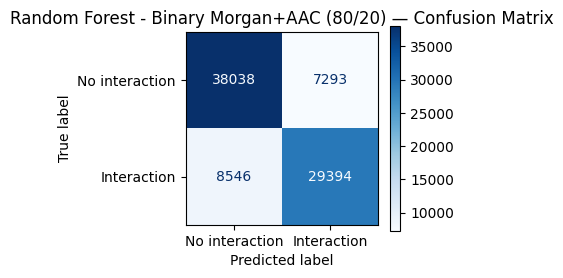


[Random Forest - Count Morgan+AAC — 80/20]  train (333080, 2068) | test (83271, 2068)

  Random Forest - Count Morgan+AAC (80/20)
  Accuracy : 0.8101
  ROC-AUC  : 0.8847
                precision    recall  f1-score   support

No interaction       0.82      0.84      0.83     45331
   Interaction       0.80      0.77      0.79     37940

      accuracy                           0.81     83271
     macro avg       0.81      0.81      0.81     83271
  weighted avg       0.81      0.81      0.81     83271



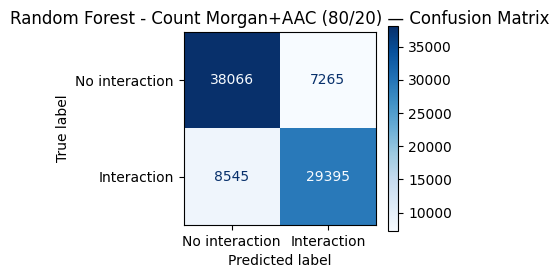


[Random Forest - MACCS+AAC — 80/20]  train (333080, 187) | test (83271, 187)

  Random Forest - MACCS+AAC (80/20)
  Accuracy : 0.7960
  ROC-AUC  : 0.8665
                precision    recall  f1-score   support

No interaction       0.81      0.82      0.81     45331
   Interaction       0.78      0.77      0.77     37940

      accuracy                           0.80     83271
     macro avg       0.79      0.79      0.79     83271
  weighted avg       0.80      0.80      0.80     83271



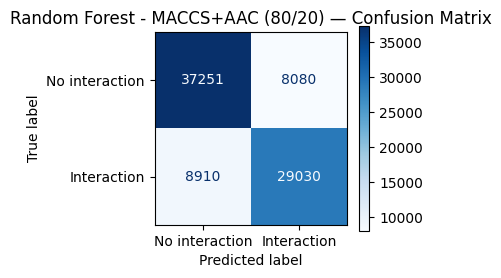


[Random Forest - Binary Morgan+DPC — 80/20]  train (333080, 2448) | test (83271, 2448)

  Random Forest - Binary Morgan+DPC (80/20)
  Accuracy : 0.8109
  ROC-AUC  : 0.8909
                precision    recall  f1-score   support

No interaction       0.83      0.82      0.82     45331
   Interaction       0.79      0.80      0.79     37940

      accuracy                           0.81     83271
     macro avg       0.81      0.81      0.81     83271
  weighted avg       0.81      0.81      0.81     83271



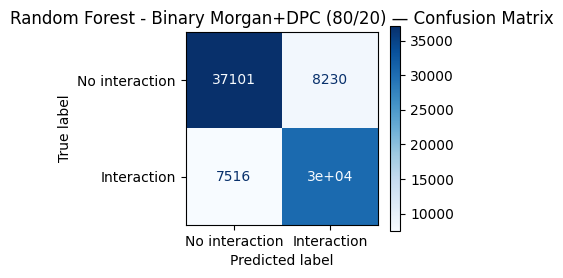


[Random Forest - Count Morgan+DPC — 80/20]  train (333080, 2448) | test (83271, 2448)

  Random Forest - Count Morgan+DPC (80/20)
  Accuracy : 0.8126
  ROC-AUC  : 0.8922
                precision    recall  f1-score   support

No interaction       0.83      0.82      0.83     45331
   Interaction       0.79      0.80      0.80     37940

      accuracy                           0.81     83271
     macro avg       0.81      0.81      0.81     83271
  weighted avg       0.81      0.81      0.81     83271



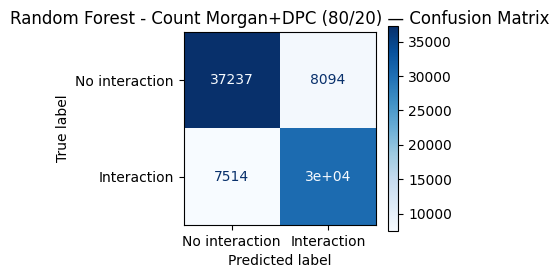


[Random Forest - MACCS+DPC — 80/20]  train (333080, 567) | test (83271, 567)

  Random Forest - MACCS+DPC (80/20)
  Accuracy : 0.7963
  ROC-AUC  : 0.8730
                precision    recall  f1-score   support

No interaction       0.82      0.81      0.81     45331
   Interaction       0.77      0.78      0.78     37940

      accuracy                           0.80     83271
     macro avg       0.79      0.80      0.79     83271
  weighted avg       0.80      0.80      0.80     83271



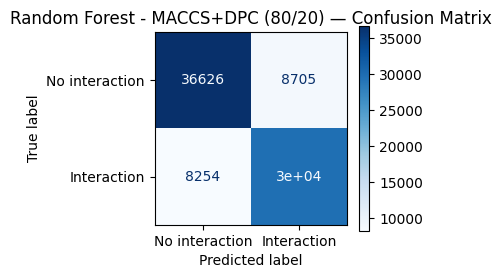


[Random Forest - Binary Morgan+AAC+DPC — 80/20]  train (333080, 2468) | test (83271, 2468)

  Random Forest - Binary Morgan+AAC+DPC (80/20)
  Accuracy : 0.8109
  ROC-AUC  : 0.8908
                precision    recall  f1-score   support

No interaction       0.83      0.82      0.83     45331
   Interaction       0.79      0.80      0.79     37940

      accuracy                           0.81     83271
     macro avg       0.81      0.81      0.81     83271
  weighted avg       0.81      0.81      0.81     83271



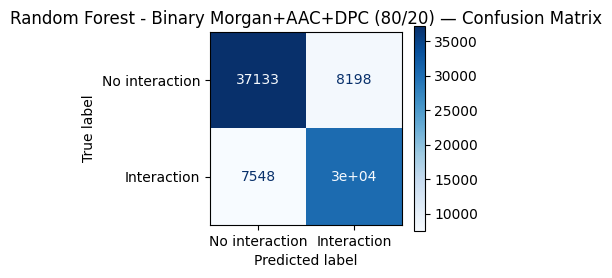


[Random Forest - Count Morgan+AAC+DPC — 80/20]  train (333080, 2468) | test (83271, 2468)

  Random Forest - Count Morgan+AAC+DPC (80/20)
  Accuracy : 0.8117
  ROC-AUC  : 0.8922
                precision    recall  f1-score   support

No interaction       0.83      0.82      0.83     45331
   Interaction       0.79      0.80      0.80     37940

      accuracy                           0.81     83271
     macro avg       0.81      0.81      0.81     83271
  weighted avg       0.81      0.81      0.81     83271



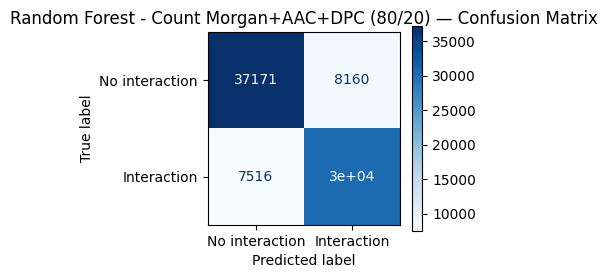


[Random Forest - MACCS+AAC+DPC — 80/20]  train (333080, 587) | test (83271, 587)

  Random Forest - MACCS+AAC+DPC (80/20)
  Accuracy : 0.7964
  ROC-AUC  : 0.8733
                precision    recall  f1-score   support

No interaction       0.82      0.81      0.81     45331
   Interaction       0.77      0.78      0.78     37940

      accuracy                           0.80     83271
     macro avg       0.79      0.80      0.79     83271
  weighted avg       0.80      0.80      0.80     83271



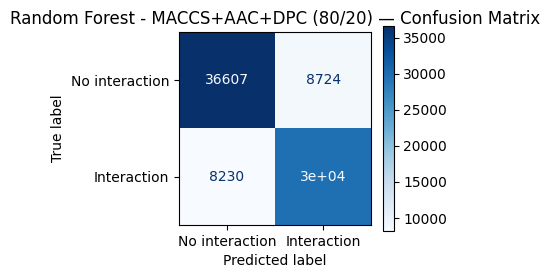

In [21]:
# ── Feature matrices and labels ───────────────────────────────────────────────
# All 9 combinations are tested to find the best-performing representation.
# ─────────────────────────────────────────────────────────────
# FEATURE MATRICES AND LABELS
# ─────────────────────────────────────────────────────────────

X_list = [
    X_Morgan_b_aac, X_Morgan_ct_aac, X_MACCS_aac,
    X_Morgan_b_DPC, X_Morgan_ct_DPC, X_MACCS_DPC,
    X_Morgan_b_aac_dpc, X_Morgan_ct_aac_dpc, X_MACCS_aac_DPC
]

names = [
    "Random Forest - Binary Morgan+AAC", "Random Forest - Count Morgan+AAC", "Random Forest - MACCS+AAC",
    "Random Forest - Binary Morgan+DPC", "Random Forest - Count Morgan+DPC", "Random Forest - MACCS+DPC",
    "Random Forest - Binary Morgan+AAC+DPC", "Random Forest - Count Morgan+AAC+DPC", "Random Forest - MACCS+AAC+DPC"
]

# ─────────────────────────────────────────────────────────────
# STORAGE
# ─────────────────────────────────────────────────────────────

rf_results = {}
roc_data = {}

# ─────────────────────────────────────────────────────────────
# EVALUATION FUNCTION
# ─────────────────────────────────────────────────────────────

def evaluate(label, model, X_test, y_test):

    y_pred  = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    print(f"\n{'='*40}")
    print(f"  {label}")
    print(f"{'='*40}")
    print(f"  Accuracy : {accuracy_score(y_test, y_pred):.4f}")
    print(f"  ROC-AUC  : {roc_auc_score(y_test, y_proba):.4f}")

    print(classification_report(
        y_test, y_pred,
        target_names=['No interaction', 'Interaction']
    ))

    fig, ax = plt.subplots(figsize=(4, 3))
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred,
        display_labels=['No interaction', 'Interaction'],
        cmap='Blues', ax=ax
    )
    ax.set_title(f'{label} — Confusion Matrix')
    plt.tight_layout()
    plt.show()

    fpr, tpr, _ = roc_curve(y_test, y_proba)
    roc_data[label] = (fpr, tpr, auc(fpr, tpr))

    return y_pred, y_proba


# ─────────────────────────────────────────────────────────────
# Train / Evaluate Classification Loop
# ─────────────────────────────────────────────────────────────

for label, X in zip(names, X_list):

    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=test_size,
        random_state=42,
        stratify=y
    )

    print(f"\n[{label} — {split_label}]  train {X_train.shape} | test {X_test.shape}")

    rf = RandomForestClassifier(
        n_estimators=100,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    )

    rf.fit(X_train, y_train)

    full_label = f"{label} ({split_label})"

    y_pred, y_proba = evaluate(full_label, rf, X_test, y_test)
    feature_names = (
        X.columns.tolist() if hasattr(X, "columns")
        else [f"f{i}" for i in range(X.shape[1])]
    )
# ─────────────────────────────────────────────────────────────
# RESULTS DICTIONARY STRUCTURE
# ─────────────────────────────────────────────────────────────

    rf_results[full_label] = {
        "model": rf,
        "Accuracy": accuracy_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_proba),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "y_test": y_test,
        "y_prob": y_proba,
        "feature_names": feature_names,
        "X_test": X_test,
    }

###XGBoost
XGBoost (Extreme Gradient Boosting) is another tree ensemble — but built very differently from Random Forest.

Core idea — BOOSTING (sequential learning):
- Tree 1 is trained on the data; it makes some errors
- Tree 2 focuses on the MISTAKES of tree 1 (harder examples get more weight)
- Tree 3 focuses on the mistakes of trees 1+2
- ... repeat for n_estimators rounds
- Final prediction = weighted SUM of all trees



In [22]:
# XGBoost (Extreme Gradient Boosting) is another tree ensemble — but built
# very differently from Random Forest.
#
# Core idea — BOOSTING (sequential learning):
#   - Tree 1 is trained on the data; it makes some errors
#   - Tree 2 focuses on the MISTAKES of tree 1 (harder examples get more weight)
#   - Tree 3 focuses on the mistakes of trees 1+2
#   - ... repeat for n_estimators rounds
#   - Final prediction = weighted SUM of all trees
#
# Random Forest vs XGBoost:
#   Random Forest  → trees are INDEPENDENT, trained in parallel, averaged
#   XGBoost        → trees are SEQUENTIAL, each corrects the previous one
#
#   Random Forest  → robust, less tuning needed, harder to overfit
#   XGBoost        → often higher accuracy, but needs more careful tuning
#
# Key parameters:
#   n_estimators=100    → number of boosting rounds (trees)
#   learning_rate=0.1   → how much each tree contributes to the final prediction
#                         lower = more conservative, needs more trees to converge
#                         typical range: 0.01 – 0.3
#   max_depth=6         → maximum depth of each tree
#                         deeper = more complex patterns, but higher overfitting risk
#                         typical range: 3 – 8
#   scale_pos_weight    → equivalent of class_weight='balanced' for XGBoost
#                         = count(negatives) / count(positives)
#                         tells XGBoost to penalise missing a positive more heavily

# Install necessary libraries
!pip install xgboost
from xgboost import XGBClassifier

# Storage dictionaries
xgb_results = {}
xgb_roc     = {}

# Store results function
def store_xgb_results(full_label, model, y_test, y_pred, y_proba, X, X_test):

    feature_names = (
        X.columns.tolist()
        if hasattr(X, "columns")
        else [f"f{i}" for i in range(X.shape[1])]
    )

    xgb_results[full_label] = {
        "model": model,
        "Accuracy": accuracy_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_proba),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "y_test": y_test,
        "y_prob": y_proba,
        "feature_names": feature_names,
        "X_test": X_test,
    }

# Shared function to train XGBoost
def xgb_model(X, label, split_label):

    # Split data
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=test_size,
        random_state=42,
        stratify=y
      )

    full_label = f"{label} ({split_label})"

    print(f"\n[{full_label}]")
    print(f"Train: {X_train.shape} | Test: {X_test.shape}")

    # Build model
    xgb_clf = XGBClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=6,
        scale_pos_weight=(
            np.bincount(y_train)[0] /
            np.bincount(y_train)[1]
        ),
        eval_metric='logloss',
        random_state=42,
        n_jobs=-1
    )

    # Train
    xgb_clf.fit(X_train, y_train)

    # Predictions
    y_pred = xgb_clf.predict(X_test)
    y_proba = xgb_clf.predict_proba(X_test)[:, 1]

    # Evaluate
    evaluate(full_label, xgb_clf, X_test, y_test)

    # Store the results into xgb_results
    store_xgb_results(
        full_label,
        xgb_clf,
        y_test,
        y_pred,
        y_proba,
        X,
        X_test
     )


#### XGBOOST- Binary Morgan+protein-aac


[XGBoost - Binary Morgan+AAC (80/20)]
Train: (333080, 2068) | Test: (83271, 2068)

  XGBoost - Binary Morgan+AAC (80/20)
  Accuracy : 0.7086
  ROC-AUC  : 0.7854
                precision    recall  f1-score   support

No interaction       0.76      0.69      0.72     45331
   Interaction       0.66      0.73      0.70     37940

      accuracy                           0.71     83271
     macro avg       0.71      0.71      0.71     83271
  weighted avg       0.71      0.71      0.71     83271



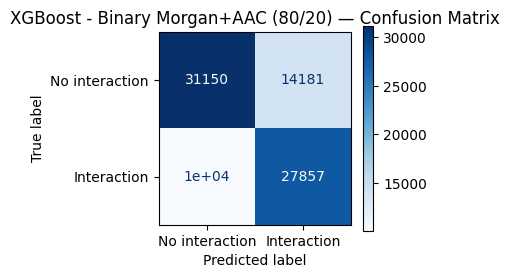

In [23]:
# ══════════════════════════════════════════════════════════════════════════════
# XGBOOST - morgan_b + protein-aac
# ══════════════════════════════════════════════════════════════════════════════

X1 = X_Morgan_b_aac

xgb_model(
    X1,
    "XGBoost - Binary Morgan+AAC",
    split_label
)

#### XGBOOST- Count Morgan-aac


[XGBoost - Count Morgan+AAC (80/20)]
Train: (333080, 2068) | Test: (83271, 2068)

  XGBoost - Count Morgan+AAC (80/20)
  Accuracy : 0.7082
  ROC-AUC  : 0.7868
                precision    recall  f1-score   support

No interaction       0.76      0.68      0.72     45331
   Interaction       0.66      0.74      0.70     37940

      accuracy                           0.71     83271
     macro avg       0.71      0.71      0.71     83271
  weighted avg       0.71      0.71      0.71     83271



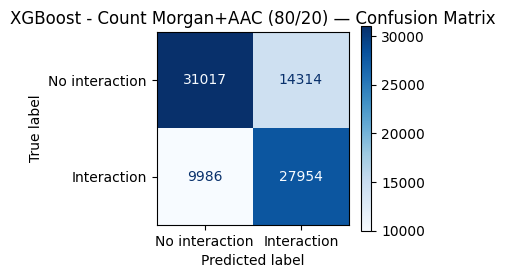

In [24]:
# ══════════════════════════════════════════════════════════════════════════════
# XGBOOST- Morgan_ct-aac
# ══════════════════════════════════════════════════════════════════════════════
X2 = X_Morgan_ct_aac

xgb_model(
    X2,
    "XGBoost - Count Morgan+AAC",
    split_label
)

#### XGBOOST- maccs-aac


[XGBoost - MACCS+AAC (80/20)]
Train: (333080, 187) | Test: (83271, 187)

  XGBoost - MACCS+AAC (80/20)
  Accuracy : 0.7012
  ROC-AUC  : 0.7807
                precision    recall  f1-score   support

No interaction       0.76      0.66      0.71     45331
   Interaction       0.65      0.75      0.69     37940

      accuracy                           0.70     83271
     macro avg       0.70      0.70      0.70     83271
  weighted avg       0.71      0.70      0.70     83271



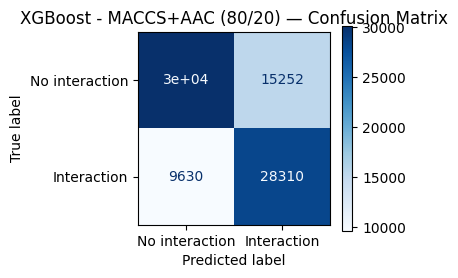

In [25]:
# ══════════════════════════════════════════════════════════════════════════════
# XGBOOST- maccs-aac
# ══════════════════════════════════════════════════════════════════════════════
X3 = X_MACCS_aac

xgb_model(
    X3,
    "XGBoost - MACCS+AAC",
    split_label
)

#### XGBOOST- Binary Morgan-DPC


[XGBoost - Binary Morgan+DPC (80/20)]
Train: (333080, 2448) | Test: (83271, 2448)

  XGBoost - Binary Morgan+DPC (80/20)
  Accuracy : 0.7240
  ROC-AUC  : 0.8044
                precision    recall  f1-score   support

No interaction       0.77      0.71      0.74     45331
   Interaction       0.68      0.74      0.71     37940

      accuracy                           0.72     83271
     macro avg       0.72      0.73      0.72     83271
  weighted avg       0.73      0.72      0.72     83271



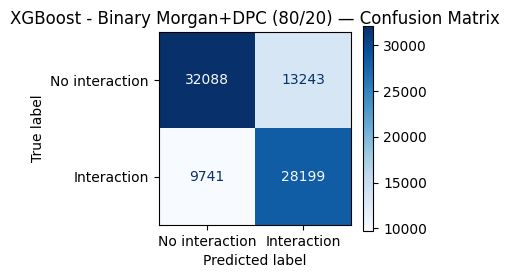

In [26]:
# ══════════════════════════════════════════════════════════════════════════════
# XGBOOST- Morgan_b-DPC
# ══════════════════════════════════════════════════════════════════════════════
X4 = X_Morgan_b_DPC

xgb_model(
    X4,
    "XGBoost - Binary Morgan+DPC",
    split_label
)

####XGBOOST- Count Morgan-DPC


[XGBoost - Count Morgan+DPC (80/20)]
Train: (333080, 2448) | Test: (83271, 2448)

  XGBoost - Count Morgan+DPC (80/20)
  Accuracy : 0.7241
  ROC-AUC  : 0.8057
                precision    recall  f1-score   support

No interaction       0.77      0.70      0.74     45331
   Interaction       0.68      0.75      0.71     37940

      accuracy                           0.72     83271
     macro avg       0.72      0.73      0.72     83271
  weighted avg       0.73      0.72      0.72     83271



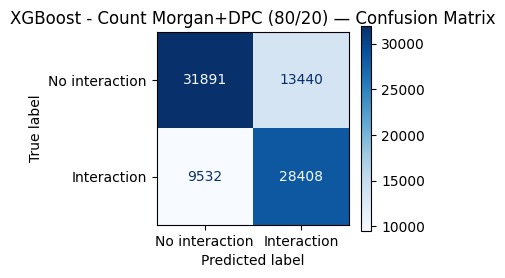

In [27]:
# ══════════════════════════════════════════════════════════════════════════════
# XGBOOST- Morgan_ct-DPC
# ══════════════════════════════════════════════════════════════════════════════
X5 = X_Morgan_ct_DPC

xgb_model(
    X5,
    "XGBoost - Count Morgan+DPC",
    split_label
)

#### XGBOOST- MACCS-DPC


[XGBoost - MACCS+DPC (80/20)]
Train: (333080, 567) | Test: (83271, 567)

  XGBoost - MACCS+DPC (80/20)
  Accuracy : 0.7178
  ROC-AUC  : 0.7996
                precision    recall  f1-score   support

No interaction       0.77      0.69      0.73     45331
   Interaction       0.67      0.75      0.71     37940

      accuracy                           0.72     83271
     macro avg       0.72      0.72      0.72     83271
  weighted avg       0.72      0.72      0.72     83271



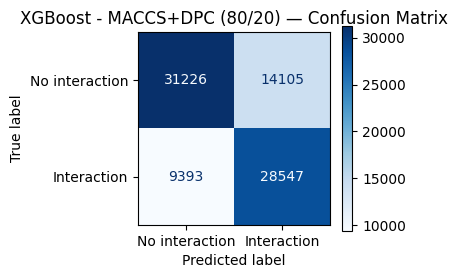

In [28]:
# ══════════════════════════════════════════════════════════════════════════════
# XGBOOST- MACCS-DPC
# ══════════════════════════════════════════════════════════════════════════════
X6 = X_MACCS_DPC

xgb_model(
    X6,
    "XGBoost - MACCS+DPC",
    split_label
)

#### XGBOOST- Binary Morgan+aac+dpc


[XGBoost - Binary Morgan+AAC+DPC (80/20)]
Train: (333080, 2468) | Test: (83271, 2468)

  XGBoost - Binary Morgan+AAC+DPC (80/20)
  Accuracy : 0.7256
  ROC-AUC  : 0.8051
                precision    recall  f1-score   support

No interaction       0.77      0.71      0.74     45331
   Interaction       0.68      0.75      0.71     37940

      accuracy                           0.73     83271
     macro avg       0.73      0.73      0.73     83271
  weighted avg       0.73      0.73      0.73     83271



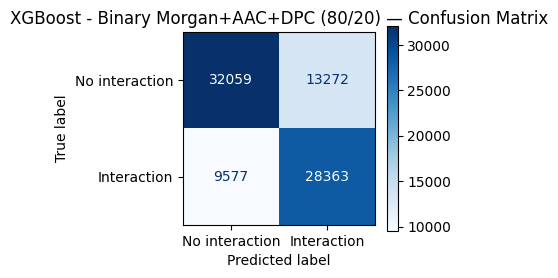

In [29]:
# ══════════════════════════════════════════════════════════════════════════════
# XGBOOST- Binary Morgan+aac+dpc
# ══════════════════════════════════════════════════════════════════════════════
X7 = X_Morgan_b_aac_dpc

xgb_model(
    X7,
    "XGBoost - Binary Morgan+AAC+DPC",
    split_label
)

#### XGBOOST- Count Morgan+aac+dpc


[XGBoost - Count Morgan+AAC+DPC (80/20)]
Train: (333080, 2468) | Test: (83271, 2468)

  XGBoost - Count Morgan+AAC+DPC (80/20)
  Accuracy : 0.7247
  ROC-AUC  : 0.8055
                precision    recall  f1-score   support

No interaction       0.77      0.70      0.74     45331
   Interaction       0.68      0.75      0.71     37940

      accuracy                           0.72     83271
     macro avg       0.73      0.73      0.72     83271
  weighted avg       0.73      0.72      0.73     83271



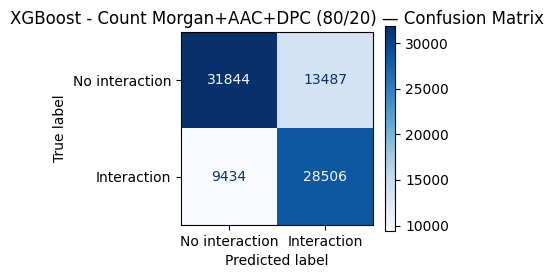

In [30]:
# ══════════════════════════════════════════════════════════════════════════════
# XGBOOST- Count Morgan+aac+dpc
# ══════════════════════════════════════════════════════════════════════════════
X8 = X_Morgan_ct_aac_dpc

xgb_model(
    X8,
    "XGBoost - Count Morgan+AAC+DPC",
    split_label
)

####XGBOOST- MACCS+AAC+DPC


[XGBoost - MACCS+AAC+DPC (80/20)]
Train: (333080, 587) | Test: (83271, 587)

  XGBoost - MACCS+AAC+DPC (80/20)
  Accuracy : 0.7174
  ROC-AUC  : 0.7984
                precision    recall  f1-score   support

No interaction       0.77      0.69      0.73     45331
   Interaction       0.67      0.75      0.71     37940

      accuracy                           0.72     83271
     macro avg       0.72      0.72      0.72     83271
  weighted avg       0.72      0.72      0.72     83271



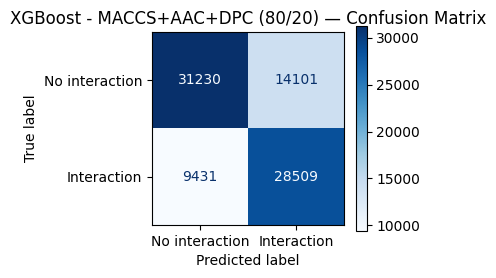

In [31]:
# ══════════════════════════════════════════════════════════════════════════════
# XGBOOST- MACCS+aac+dpc
# ══════════════════════════════════════════════════════════════════════════════
X9 = X_MACCS_aac_DPC

xgb_model(
    X9,
    "XGBoost - MACCS+AAC+DPC",
    split_label
)

Random Forest vs XGBoost:

Random Forest  
→ trees are INDEPENDENT, trained in parallel, averaged

→ robust, less tuning needed, harder to overfit

XGBoost        
→ trees are SEQUENTIAL, each corrects the previous one

→ often higher accuracy, but needs more careful tuning

##Visualization

In [32]:
# ── Shared config ─────────────────────────────────────────────────────────────
metrics = ['Accuracy', 'ROC-AUC', 'Precision', 'Recall', 'F1']
short_names = [
    "Binary Morgan+AAC", "Count Morgan+AAC", "MACCS+AAC",
    "Binary Morgan+DPC", "Count Morgan+DPC", "MACCS+DPC",
    "Binary Morgan+AAC+DPC", "Count Morgan+AAC+DPC", "MACCS+AAC+DPC"
]
rows = []

# ─────────────────────────────────────────────
# LOOP THROUGH RF RESULTS (PAIR WITH XGB)
# ─────────────────────────────────────────────

for rf_key in rf_results.keys():

    # match corresponding XGBoost key
    xgb_key = rf_key.replace("Random Forest", "XGBoost")

    # skip if pair missing
    if xgb_key not in xgb_results:
        continue

    rf = rf_results[rf_key]
    xgb = xgb_results[xgb_key]

    # extract representation name (clean label)
    representation = rf_key.replace("Random Forest - ", "").split(" (")[0]

    row = {"Representation": representation}

    # ─────────────────────────────────────────────
    # ADD RF METRICS
    # ─────────────────────────────────────────────
    for m in metrics:
        row[f"RF_{m}"] = rf[m]

    # ─────────────────────────────────────────────
    # ADD XGB METRICS
    # ─────────────────────────────────────────────
    for m in metrics:
        row[f"XGB_{m}"] = xgb[m]

    rows.append(row)

# ─────────────────────────────────────────────
# CREATE  DATAFRAME
# ─────────────────────────────────────────────

results_df = pd.DataFrame(rows)

# ─────────────────────────────────────────────
# OUTPUT
# ─────────────────────────────────────────────

print(results_df)

          Representation  RF_Accuracy  RF_ROC-AUC  RF_Precision  RF_Recall  \
0      Binary Morgan+AAC     0.809790    0.883532      0.801210   0.774750   
1       Count Morgan+AAC     0.810138    0.884686      0.801828   0.774776   
2              MACCS+AAC     0.795967    0.866481      0.782269   0.765156   
3      Binary Morgan+DPC     0.810907    0.890929      0.787085   0.801898   
4       Count Morgan+DPC     0.812564    0.892216      0.789875   0.801950   
5              MACCS+DPC     0.796340    0.872988      0.773254   0.782446   
6  Binary Morgan+AAC+DPC     0.810907    0.890788      0.787562   0.801054   
7   Count Morgan+AAC+DPC     0.811747    0.892200      0.788513   0.801898   
8          MACCS+AAC+DPC     0.796400    0.873326      0.773013   0.783079   

      RF_F1  XGB_Accuracy  XGB_ROC-AUC  XGB_Precision  XGB_Recall    XGB_F1  
0  0.787758      0.708614     0.785416       0.662662    0.734238  0.696617  
1  0.788070      0.708182     0.786754       0.661351    0.7367

###ROC Curves for RF and XGBoost separately

Binary Morgan+AAC              → RF:  Random Forest - Binary Morgan+AAC (80/20)
Binary Morgan+AAC              → XGB: XGBoost - Binary Morgan+AAC (80/20)
Count Morgan+AAC               → RF:  Random Forest - Binary Morgan+AAC+DPC (80/20)
Count Morgan+AAC               → XGB: XGBoost - Binary Morgan+AAC+DPC (80/20)
MACCS+AAC                      → RF:  Random Forest - Count Morgan+AAC (80/20)
MACCS+AAC                      → XGB: XGBoost - Count Morgan+AAC (80/20)
Binary Morgan+DPC              → RF:  Random Forest - Count Morgan+AAC+DPC (80/20)
Binary Morgan+DPC              → XGB: XGBoost - Count Morgan+AAC+DPC (80/20)
Count Morgan+DPC               → RF:  Random Forest - MACCS+AAC (80/20)
Count Morgan+DPC               → XGB: XGBoost - MACCS+AAC (80/20)
MACCS+DPC                      → RF:  Random Forest - MACCS+AAC+DPC (80/20)
MACCS+DPC                      → XGB: XGBoost - MACCS+AAC+DPC (80/20)
Binary Morgan+AAC+DPC          → RF:  Random Forest - Binary Morgan+DPC (80/20)
Binary M

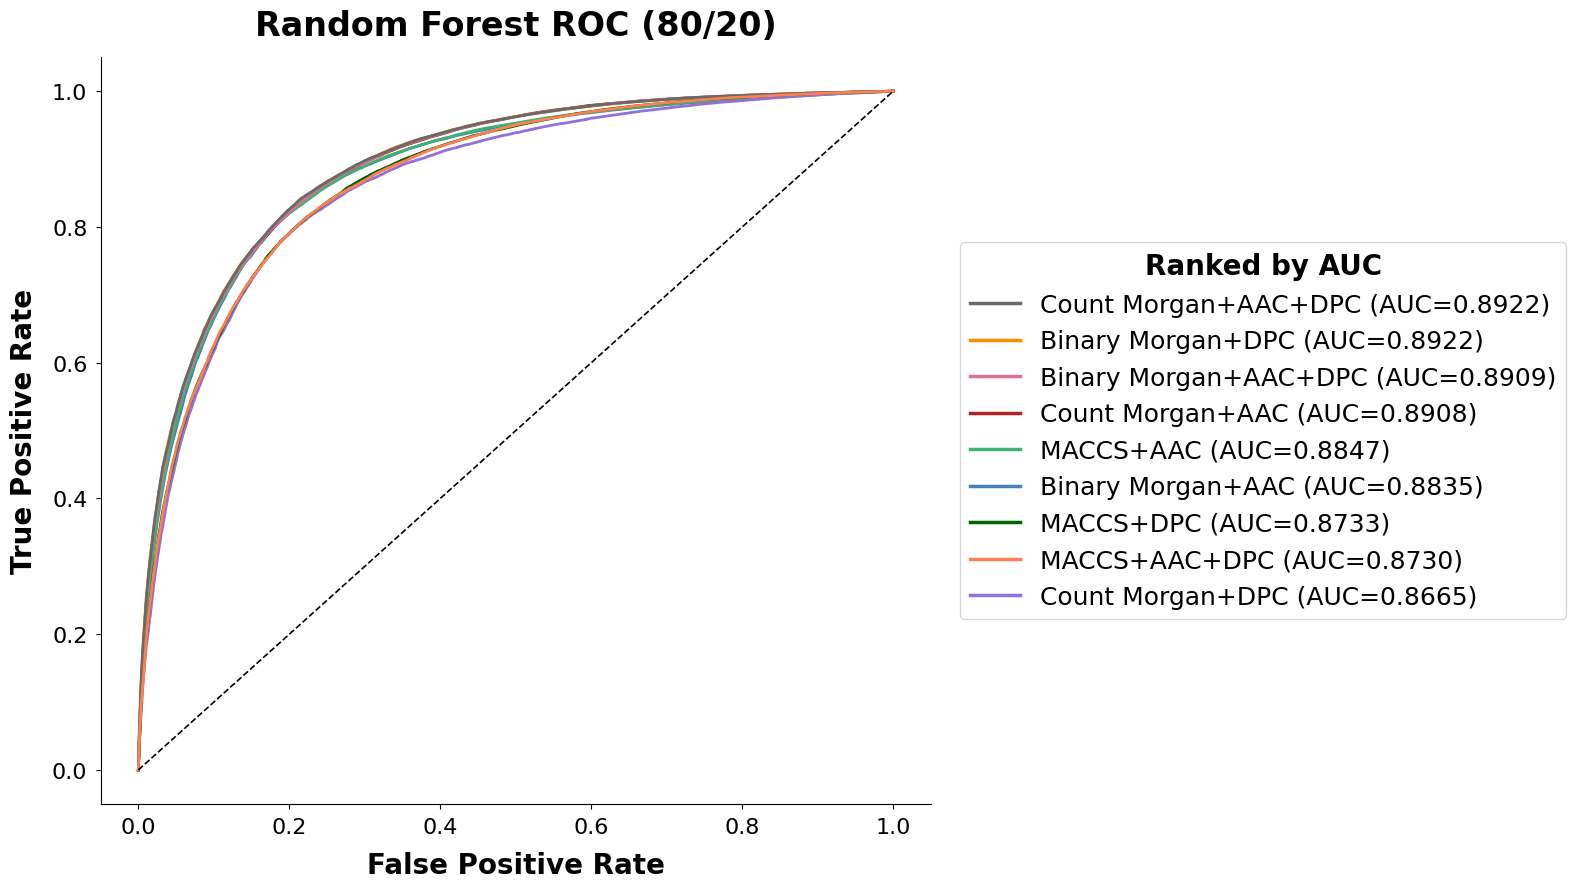


XGBoost AUC Ranking (Best → Worst)
       Representation      AUC
 Count Morgan+AAC+DPC 0.805715
    Binary Morgan+DPC 0.805494
     Count Morgan+AAC 0.805057
Binary Morgan+AAC+DPC 0.804380
        MACCS+AAC+DPC 0.799586
            MACCS+DPC 0.798423
            MACCS+AAC 0.786754
    Binary Morgan+AAC 0.785416
     Count Morgan+DPC 0.780707

★ Best XGBoost Model: Count Morgan+AAC+DPC | AUC = 0.8057


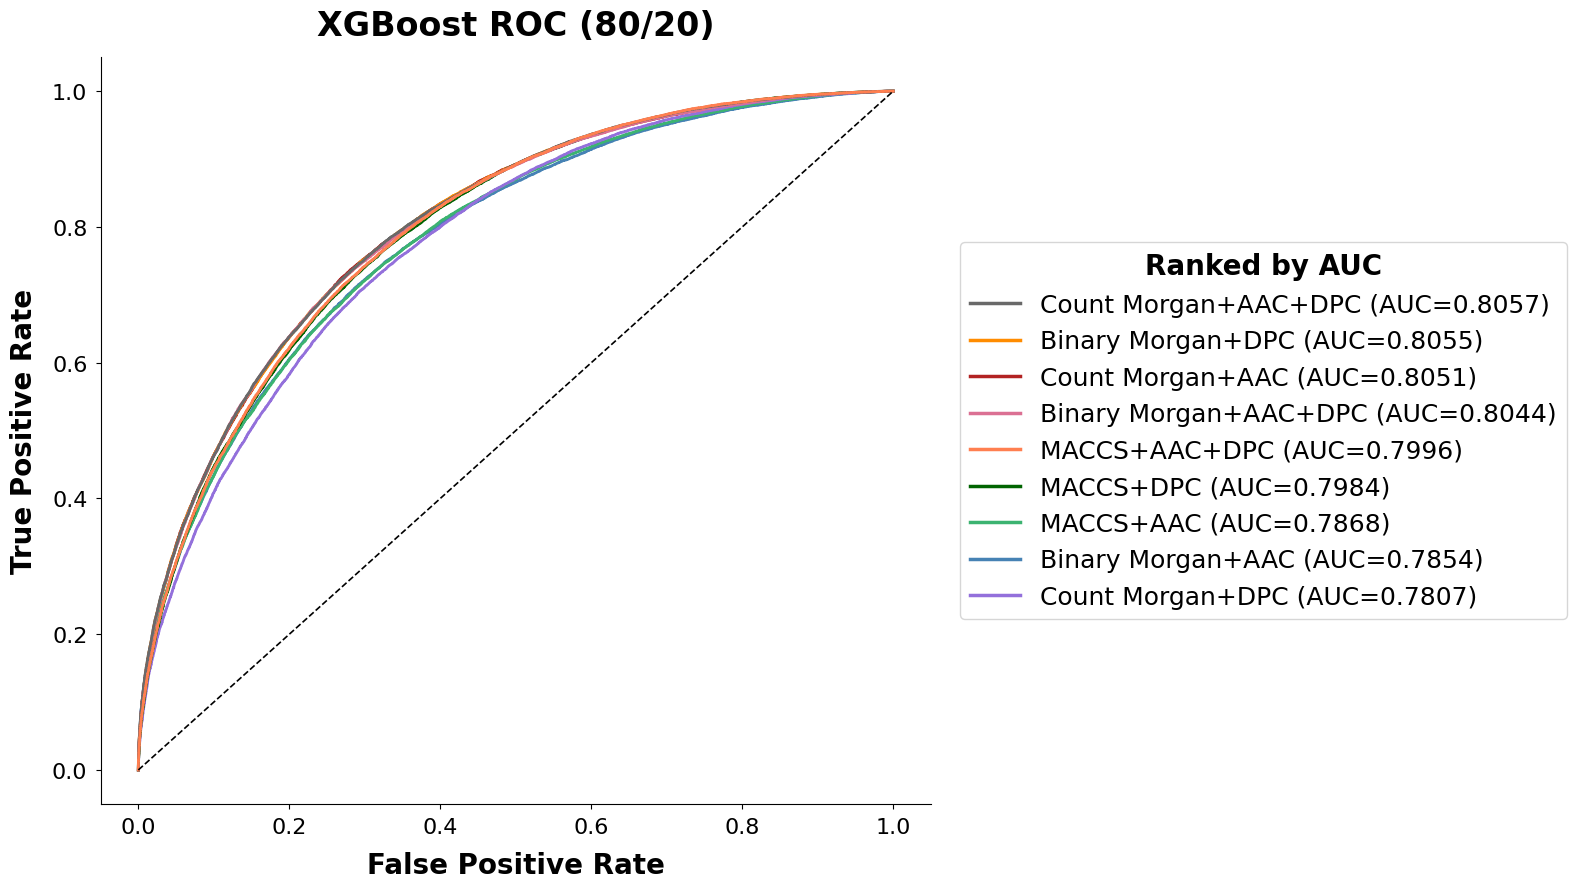

In [33]:
# ─────────────────────────────────────────────────────────────
# COLORS + CONFIG
# ─────────────────────────────────────────────────────────────

rep_colors = [
    'steelblue',      # Binary Morgan+AAC
    'firebrick',      # Count Morgan+AAC
    'mediumseagreen', # MACCS+AAC
    'darkorange',     # Binary Morgan+DPC
    'mediumpurple',   # Count Morgan+DPC
    'darkgreen',      # MACCS+DPC
    'palevioletred',  # Binary Morgan+AAC+DPC
    'dimgray',        # Count Morgan+AAC+DPC
    'coral',          # MACCS+AAC+DPC
]

FONT         = "DejaVu Sans"
TITLE_FS     = 24
LABEL_FS     = 20
TICK_FS      = 16
LEGEND_FS    = 18
LEG_TITLE_FS = 20

RF_COLOR  = 'blue'
XGB_COLOR = 'red'


# ─────────────────────────────────────────────────────────────
# KEY MAPPING
# ─────────────────────────────────────────────────────────────

rf_keys  = [k for name in short_names
              for k in rf_results.keys()
              if name in k]

xgb_keys = [k for name in short_names
               for k in xgb_results.keys()
               if name in k]

for short, rf_k, xgb_k in zip(short_names, rf_keys, xgb_keys):
    print(f"{short:30s} → RF:  {rf_k}")
    print(f"{short:30s} → XGB: {xgb_k}")


# ─────────────────────────────────────────────────────────────
# RF ROC CURVE
# ─────────────────────────────────────────────────────────────

fig, ax = plt.subplots(figsize=(13, 9))
summary_rows = []

for rf_key, short, color in zip(rf_keys, short_names, rep_colors):

    row = rf_results[rf_key]

    fpr, tpr, _ = roc_curve(row['y_test'], row['y_prob'])
    auc_score = auc(fpr, tpr)

    ax.plot(
        fpr, tpr,
        color=color,
        lw=2,
        label=f"{short} (AUC={auc_score:.4f})"
    )

    summary_rows.append({
        "Representation": short,
        "AUC": auc_score,
        "Color": color
    })

ax.plot([0, 1], [0, 1], 'k--', lw=1.2)

ax.set_title(f"Random Forest ROC ({split_label})",
             fontsize=TITLE_FS, fontweight="bold", fontfamily=FONT, pad=16)
ax.set_xlabel("False Positive Rate",
              fontsize=LABEL_FS, fontweight="bold", fontfamily=FONT, labelpad=10)
ax.set_ylabel("True Positive Rate",
              fontsize=LABEL_FS, fontweight="bold", fontfamily=FONT, labelpad=10)
ax.tick_params(axis="both", labelsize=TICK_FS, pad=6)
for label in ax.get_xticklabels() + ax.get_yticklabels():
    label.set_fontfamily(FONT)


# ─────────────────────────────────────────────────────────────
# RF RANKING TABLE
# ─────────────────────────────────────────────────────────────

summary_df = (
    pd.DataFrame(summary_rows)
    .sort_values("AUC", ascending=False)
    .reset_index(drop=True)
)

print("\nRandom Forest AUC Ranking (Best → Worst)")
print(summary_df[["Representation", "AUC"]].to_string(index=False))

best = summary_df.iloc[0]
print(f"\n★ Best Random Forest Model: {best['Representation']} | AUC = {best['AUC']:.4f}")


# ─────────────────────────────────────────────────────────────
# RF LEGEND (RANKED)
# ─────────────────────────────────────────────────────────────

legend_entries = sorted(summary_rows, key=lambda x: x["AUC"], reverse=True)

handles = [
    plt.Line2D([0], [0], color=row["Color"], lw=2.5)
    for row in legend_entries
]

labels = [
    f"{row['Representation']} (AUC={row['AUC']:.4f})"
    for row in legend_entries
]

leg = ax.legend(
    handles,
    labels,
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    ncols=1,
    fontsize=LEGEND_FS,
    frameon=True,
    title="Ranked by AUC",
    title_fontsize=LEG_TITLE_FS,
    prop={"family": FONT, "size": LEGEND_FS},
)
leg.get_title().set_fontfamily(FONT)
leg.get_title().set_fontweight("bold")

ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.subplots_adjust(right=0.72)
plt.show()


# ─────────────────────────────────────────────────────────────
# XGBOOST ROC CURVE
# ─────────────────────────────────────────────────────────────

fig, ax = plt.subplots(figsize=(13, 9))
summary_rows = []

for xgb_key, short, color in zip(xgb_keys, short_names, rep_colors):

    row = xgb_results[xgb_key]

    fpr, tpr, _ = roc_curve(row['y_test'], row['y_prob'])
    auc_score = auc(fpr, tpr)

    ax.plot(
        fpr, tpr,
        color=color,
        lw=2,
        label=f"{short} (AUC={auc_score:.4f})"
    )

    summary_rows.append({
        "Representation": short,
        "AUC": auc_score,
        "Color": color
    })

ax.plot([0, 1], [0, 1], 'k--', lw=1.2)

ax.set_title(f"XGBoost ROC ({split_label})",
             fontsize=TITLE_FS, fontweight="bold", fontfamily=FONT, pad=16)
ax.set_xlabel("False Positive Rate",
              fontsize=LABEL_FS, fontweight="bold", fontfamily=FONT, labelpad=10)
ax.set_ylabel("True Positive Rate",
              fontsize=LABEL_FS, fontweight="bold", fontfamily=FONT, labelpad=10)
ax.tick_params(axis="both", labelsize=TICK_FS, pad=6)
for label in ax.get_xticklabels() + ax.get_yticklabels():
    label.set_fontfamily(FONT)


# ─────────────────────────────────────────────────────────────
# XGB RANKING TABLE
# ─────────────────────────────────────────────────────────────

summary_df = (
    pd.DataFrame(summary_rows)
    .sort_values("AUC", ascending=False)
    .reset_index(drop=True)
)

print("\nXGBoost AUC Ranking (Best → Worst)")
print(summary_df[["Representation", "AUC"]].to_string(index=False))

best = summary_df.iloc[0]
print(f"\n★ Best XGBoost Model: {best['Representation']} | AUC = {best['AUC']:.4f}")


# ─────────────────────────────────────────────────────────────
# XGB LEGEND (RANKED)
# ─────────────────────────────────────────────────────────────

legend_entries = sorted(summary_rows, key=lambda x: x["AUC"], reverse=True)

handles = [
    plt.Line2D([0], [0], color=row["Color"], lw=2.5)
    for row in legend_entries
]

labels = [
    f"{row['Representation']} (AUC={row['AUC']:.4f})"
    for row in legend_entries
]

leg = ax.legend(
    handles,
    labels,
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    ncols=1,
    fontsize=LEGEND_FS,
    frameon=True,
    title="Ranked by AUC",
    title_fontsize=LEG_TITLE_FS,
    prop={"family": FONT, "size": LEGEND_FS},
)
leg.get_title().set_fontfamily(FONT)
leg.get_title().set_fontweight("bold")

ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.subplots_adjust(right=0.72)
plt.show()

###Faceted Bar Plots


 FEATURE SET RANKING (by Mean AUC RF+XGB)
01. Count Morgan+AAC+DPC | RF=0.892 | XGB=0.806 | Mean=0.849
02. Binary Morgan+DPC | RF=0.892 | XGB=0.805 | Mean=0.849
03. Count Morgan+AAC | RF=0.891 | XGB=0.805 | Mean=0.848
04. Binary Morgan+AAC+DPC | RF=0.891 | XGB=0.804 | Mean=0.848
05. MACCS+AAC+DPC | RF=0.873 | XGB=0.800 | Mean=0.836
06. MACCS+DPC | RF=0.873 | XGB=0.798 | Mean=0.836
07. MACCS+AAC | RF=0.885 | XGB=0.787 | Mean=0.836
08. Binary Morgan+AAC | RF=0.884 | XGB=0.785 | Mean=0.834
09. Count Morgan+DPC | RF=0.866 | XGB=0.781 | Mean=0.824


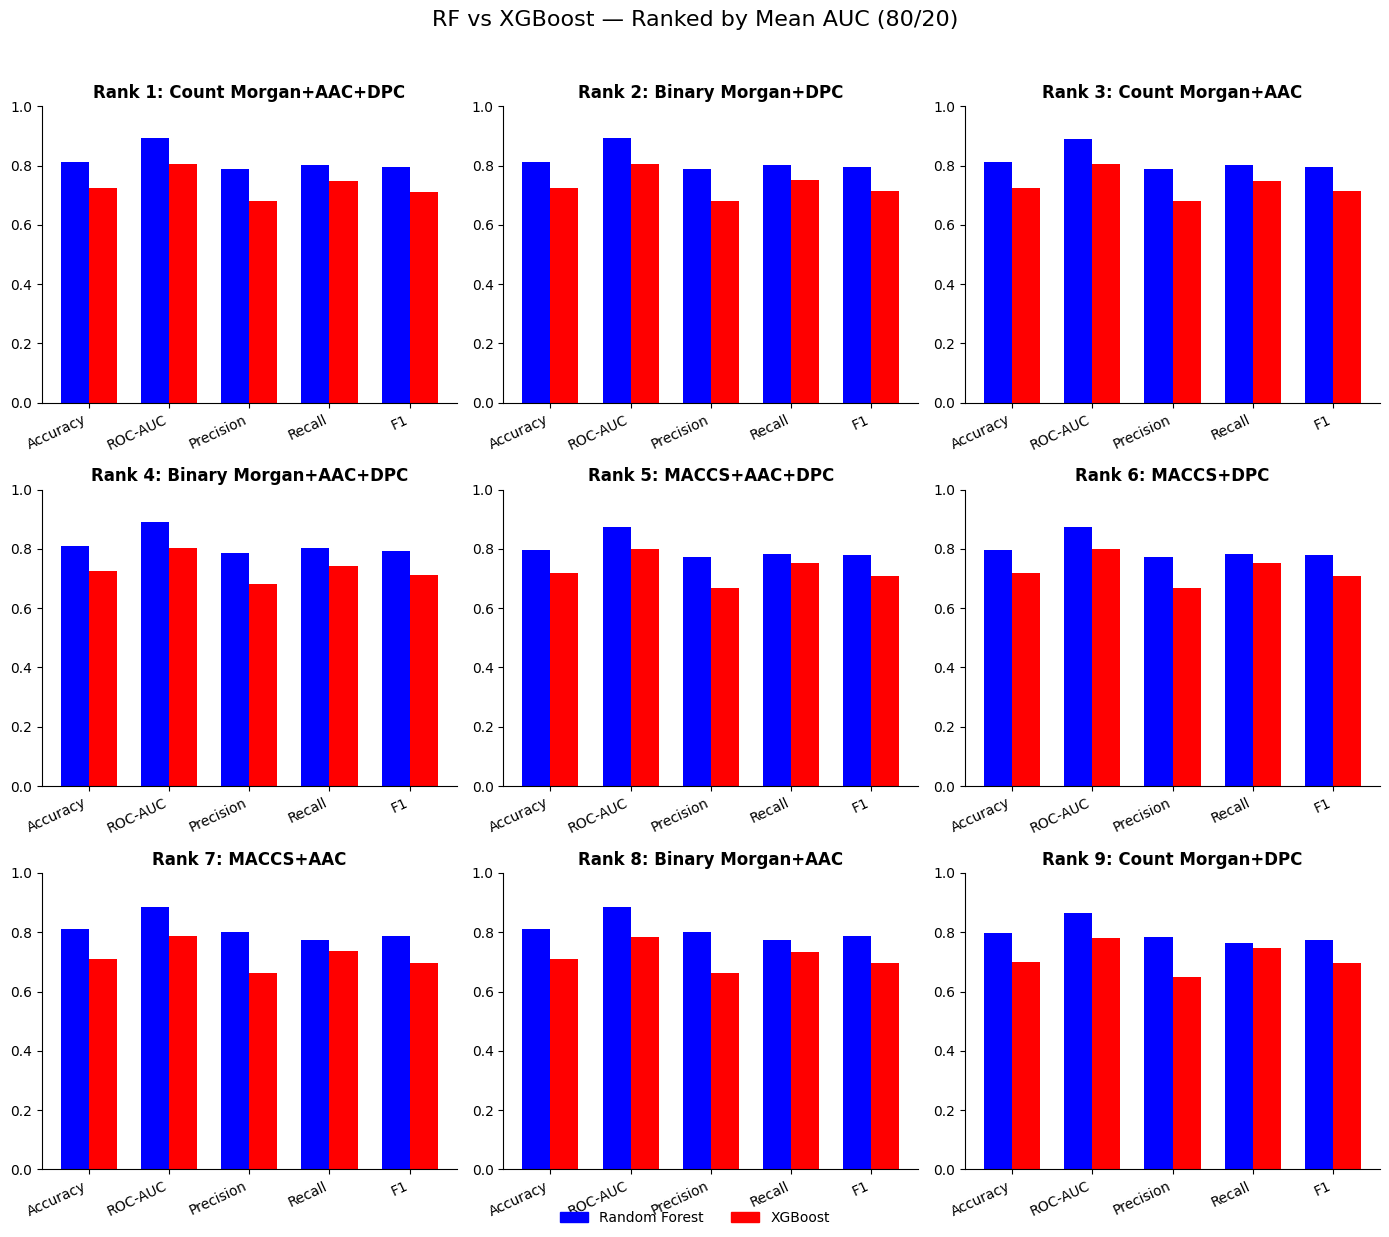

In [34]:
# ─────────────────────────────────────────────────────────────
# STEP 1: Compute ranking score (RF + XGB AUC)
# ─────────────────────────────────────────────────────────────
ranking = []

for rf_key, xgb_key, short in zip(rf_keys, xgb_keys, short_names):

    rf_row  = rf_results[rf_key]
    xgb_row = xgb_results[xgb_key]

    rf_auc  = roc_auc_score(rf_row["y_test"],  rf_row["y_prob"])
    xgb_auc = roc_auc_score(xgb_row["y_test"], xgb_row["y_prob"])

    ranking.append({
        "short": short,
        "rf_key": rf_key,
        "xgb_key": xgb_key,
        "rf_auc": rf_auc,
        "xgb_auc": xgb_auc,
        "mean_auc": (rf_auc + xgb_auc) / 2
    })


# ─────────────────────────────────────────────────────────────
# STEP 2: Sort by performance
# ─────────────────────────────────────────────────────────────

ranking = sorted(ranking, key=lambda x: x["mean_auc"], reverse=True)

print("\n FEATURE SET RANKING (by Mean AUC RF+XGB)")
for i, r in enumerate(ranking, 1):
    print(
        f"{i:02d}. {r['short']} | "
        f"RF={r['rf_auc']:.3f} | "
        f"XGB={r['xgb_auc']:.3f} | "
        f"Mean={r['mean_auc']:.3f}"
    )


# ─────────────────────────────────────────────────────────────
# STEP 3: Plot ranked performance comparison
# ─────────────────────────────────────────────────────────────

ncols = 3
nrows = int(np.ceil(len(ranking) / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(14, 4 * nrows))
axes = axes.flatten()

x = np.arange(len(metrics))
width = 0.35

for i, item in enumerate(ranking):

    ax = axes[i]

    rf_scores  = [rf_results[item["rf_key"]][m] for m in metrics]
    xgb_scores = [xgb_results[item["xgb_key"]][m] for m in metrics]

    ax.bar(x - width/2, rf_scores,  width, color=RF_COLOR)
    ax.bar(x + width/2, xgb_scores, width, color=XGB_COLOR)

    ax.set_title(f"Rank {i+1}: {item['short']}", fontsize=12, fontweight="bold")

    ax.set_xticks(x)
    ax.set_xticklabels(metrics, rotation=25, ha="right")
    ax.set_ylim(0, 1)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


# Hide unused subplots
for j in range(len(ranking), len(axes)):
    axes[j].axis("off")


# Legend
fig.legend(
    handles=[
        Patch(color=RF_COLOR,  label="Random Forest"),
        Patch(color=XGB_COLOR, label="XGBoost")
    ],
    loc="lower center",
    ncol=2,
    frameon=False
)

fig.suptitle(
    f"RF vs XGBoost — Ranked by Mean AUC ({split_label})",
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()

### Distribution plots (RF vs XGB)

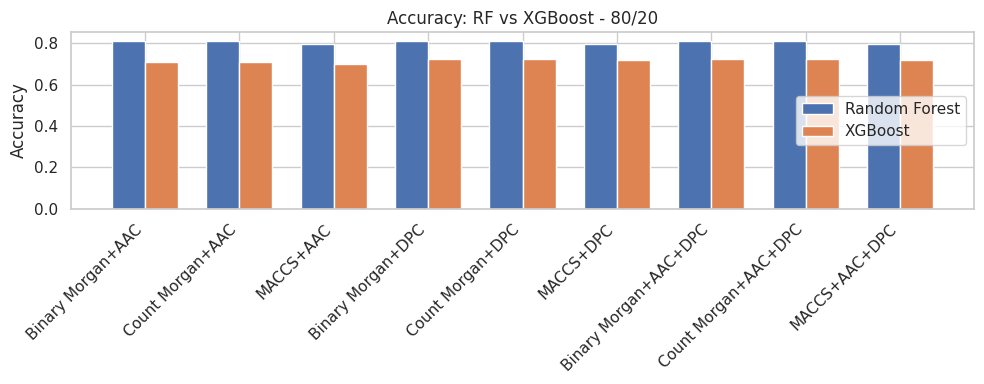

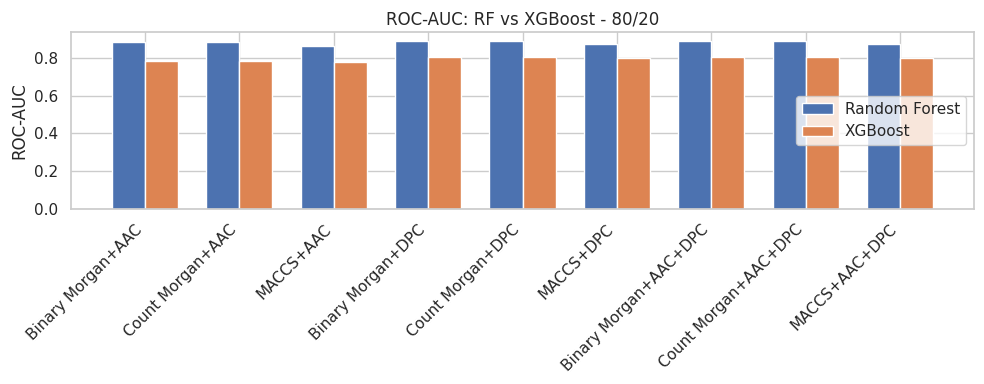

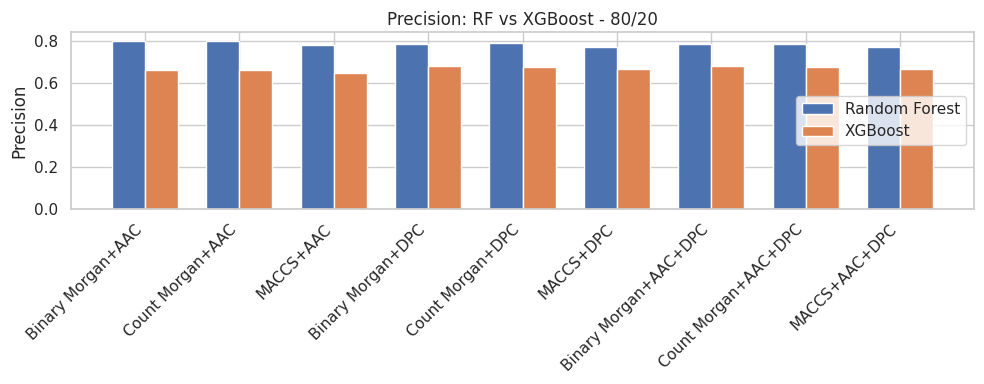

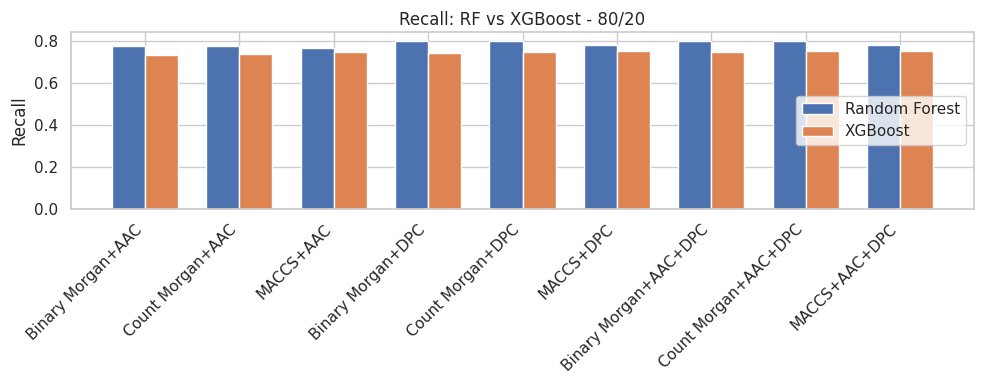

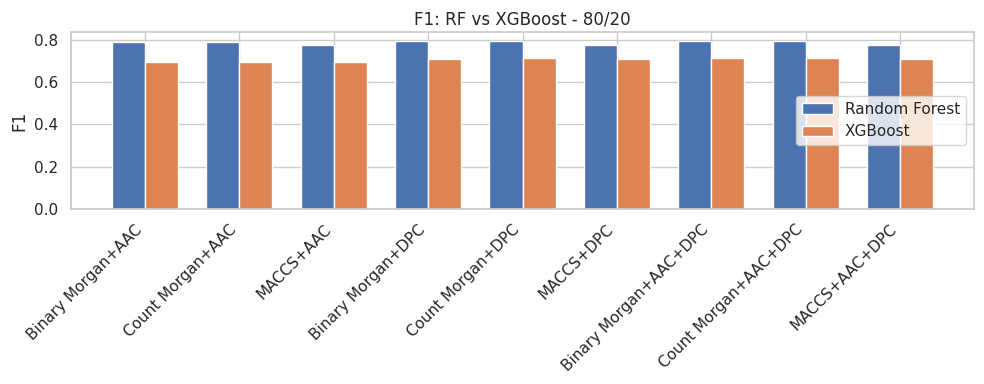

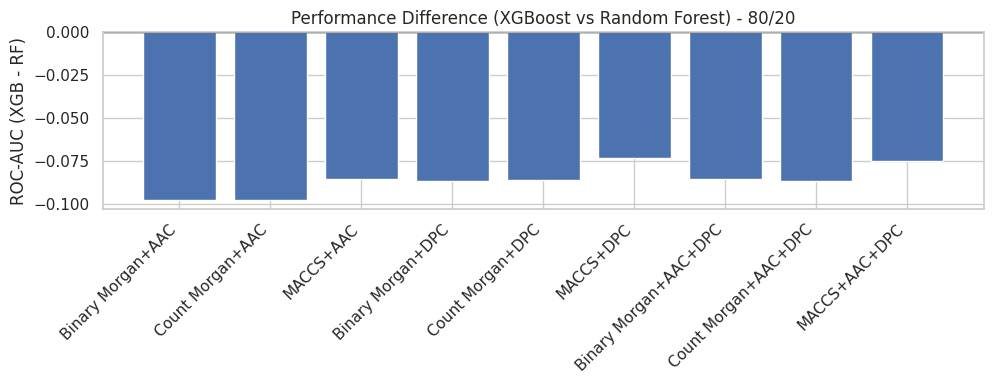

In [35]:
# ===============================
# CLEAN VISUALIZATION PIPELINE
# RF vs XGB (WIDE DATAFRAME)
# ===============================
sns.set(style="whitegrid")

x = np.arange(len(results_df["Representation"]))
width = 0.35

for m in metrics:

    plt.figure(figsize=(10, 4))

    plt.bar(
        x - width/2,
        results_df[f"RF_{m}"],
        width,
        label="Random Forest"
    )

    plt.bar(
        x + width/2,
        results_df[f"XGB_{m}"],
        width,
        label="XGBoost"
    )

    plt.xticks(x, results_df["Representation"], rotation=45, ha="right")
    plt.ylabel(m)
    plt.title(f"{m}: RF vs XGBoost - {split_label}")
    plt.legend(loc="center right")

    plt.tight_layout()
    plt.show()

# DELTA PLOT (XGB - RF)
plt.figure(figsize=(10, 4))

delta = results_df["XGB_ROC-AUC"] - results_df["RF_ROC-AUC"]

plt.bar(results_df["Representation"], delta)

plt.axhline(0, color="black", linewidth=1)

plt.xticks(rotation=45, ha="right")

plt.ylabel("ROC-AUC (XGB - RF)")
plt.title(f"Performance Difference (XGBoost vs Random Forest) - {split_label}")

plt.tight_layout()
plt.show()

### Heatmap
* RF vs XGB × 9 representations

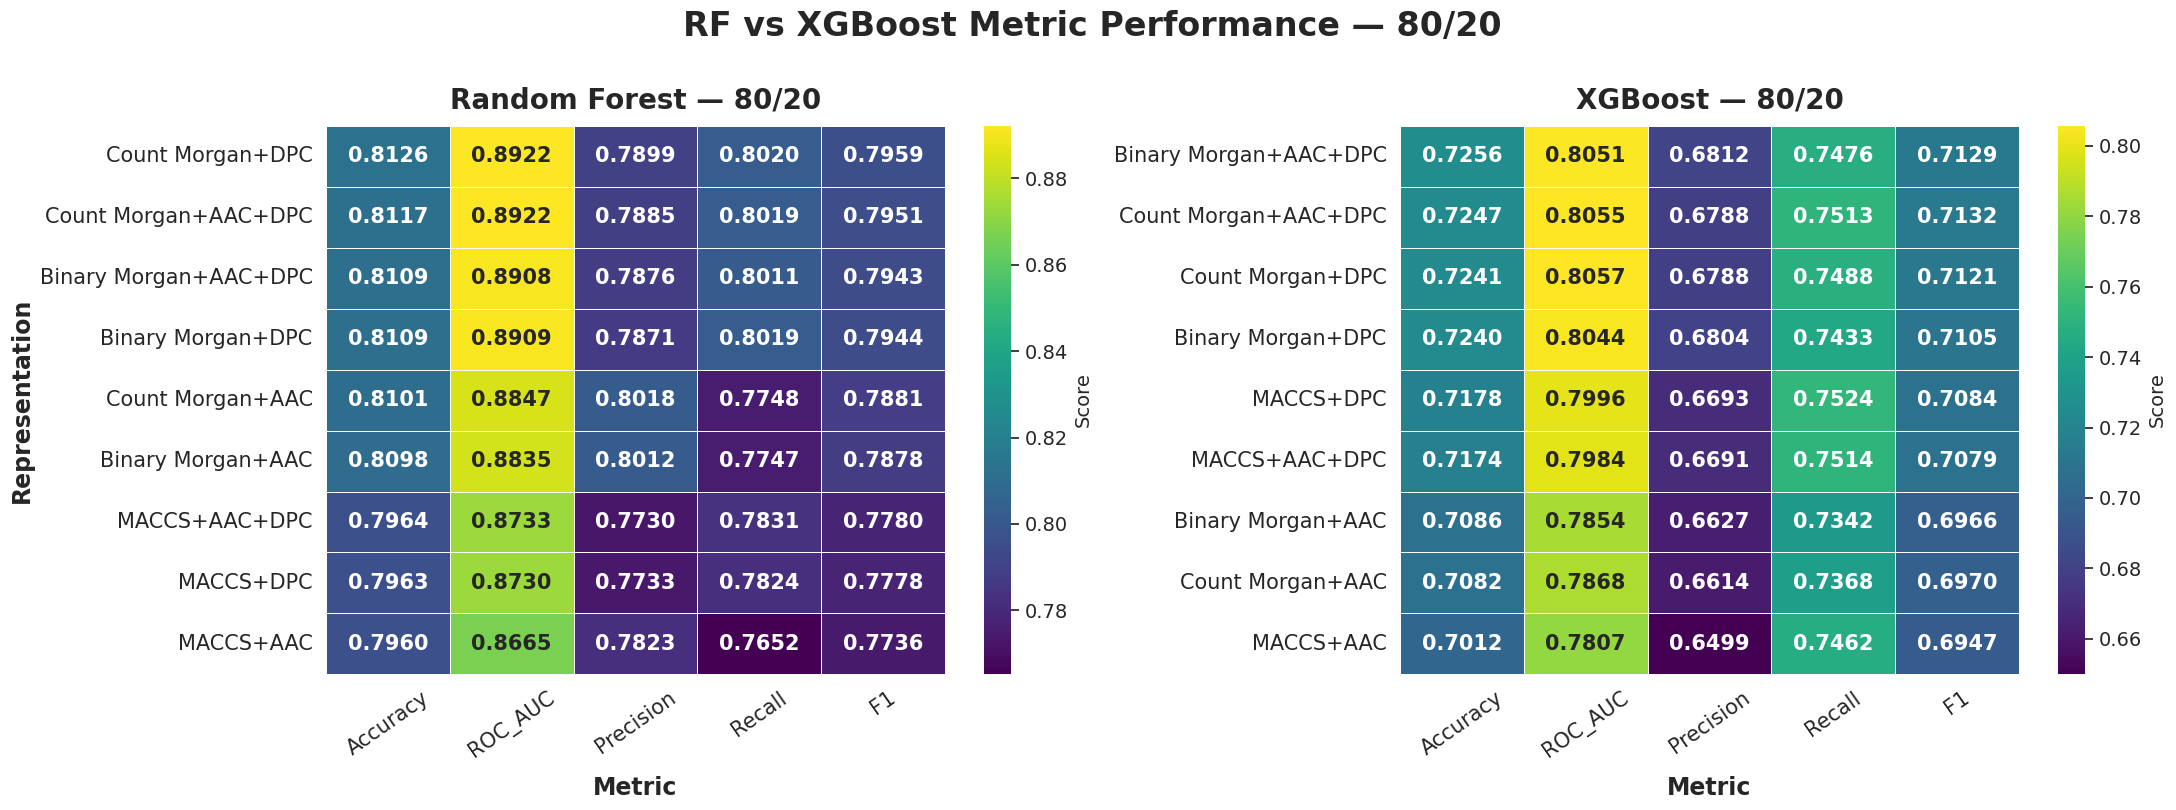

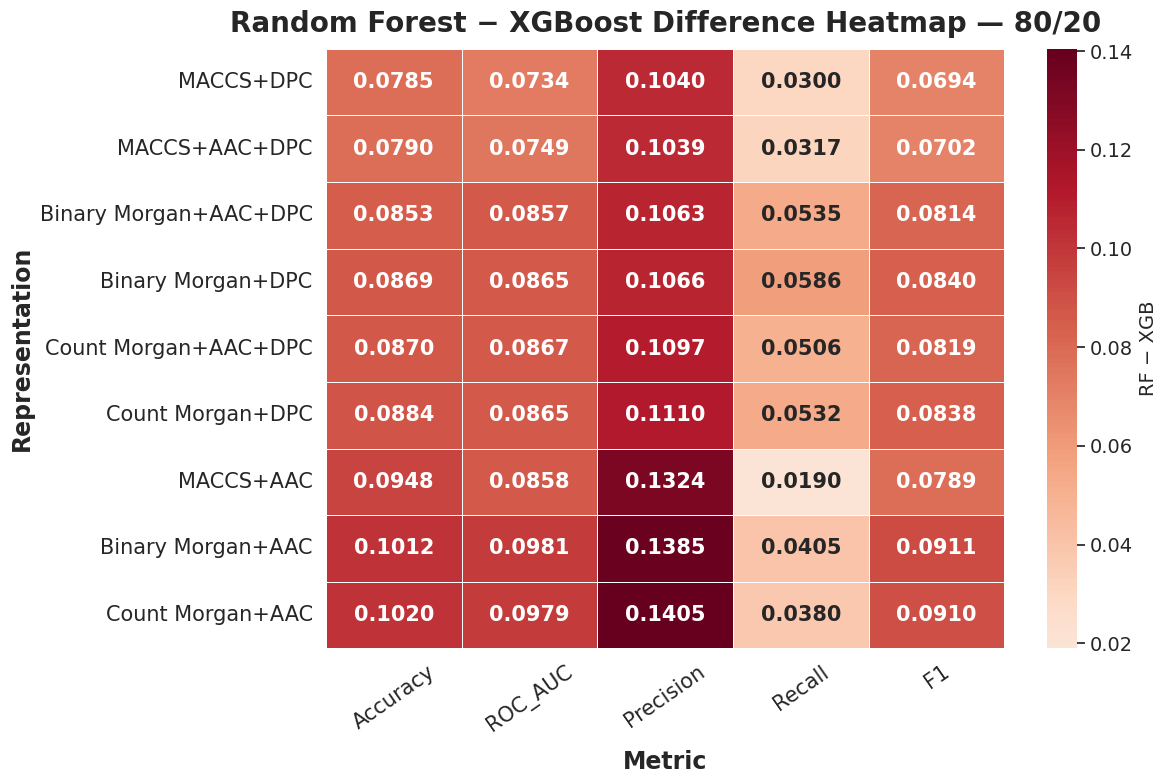

In [36]:
# ─────────────────────────────────────────────
# STEP 0: LOAD DATA
# ─────────────────────────────────────────────

df_r = results_df.copy()

df_r.columns = (
    df_r.columns
    .str.replace("-", "_")
    .str.replace(" ", "_")
)

metrics = [m.replace("-", "_").replace(" ", "_") for m in metrics]

# ─────────────────────────────────────────────
# STEP 1: PIVOT RF & XGB — each sorted by own accuracy
# ─────────────────────────────────────────────

rf_cols  = [f"RF_{m}"  for m in metrics if f"RF_{m}"  in df_r.columns]
xgb_cols = [f"XGB_{m}" for m in metrics if f"XGB_{m}" in df_r.columns]

rf_heat = (
    df_r.sort_values("RF_Accuracy", ascending=False)
    .set_index("Representation")[rf_cols]
)
rf_heat.columns = [c.replace("RF_", "") for c in rf_heat.columns]

xgb_heat = (
    df_r.sort_values("XGB_Accuracy", ascending=False)
    .set_index("Representation")[xgb_cols]
)
xgb_heat.columns = [c.replace("XGB_", "") for c in xgb_heat.columns]

# ─────────────────────────────────────────────
# STEP 2: RF & XGB HEATMAPS SIDE BY SIDE
# ─────────────────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(22, 8))

TITLE_FS  = 20
LABEL_FS  = 17
TICK_FS   = 15
ANNOT_FS  = 15
CBAR_FS   = 14

for ax, heat, title in [
    (axes[0], rf_heat,  f"Random Forest — {split_label}"),
    (axes[1], xgb_heat, f"XGBoost — {split_label}"),
]:
    sns.heatmap(
        heat,
        annot=True,
        fmt=".4f",
        cmap="viridis",
        linewidths=0.5,
        ax=ax,
        cbar_kws={"label": "Score"},
        annot_kws={"size": ANNOT_FS, "weight": "bold", "family": "DejaVu Sans"},
    )
    ax.set_title(title, fontsize=TITLE_FS, fontweight="bold", fontfamily="DejaVu Sans", pad=12)
    ax.set_xlabel("Metric",  fontsize=LABEL_FS, fontweight="bold", fontfamily="DejaVu Sans", labelpad=10)
    ax.tick_params(axis="x", rotation=35, labelsize=TICK_FS)
    ax.tick_params(axis="y", rotation=0,  labelsize=TICK_FS)
    ax.yaxis.set_tick_params(labelsize=TICK_FS)
    for lbl in ax.get_xticklabels() + ax.get_yticklabels():
        lbl.set_fontfamily("DejaVu Sans")
    ax.collections[0].colorbar.ax.tick_params(labelsize=CBAR_FS)
    ax.collections[0].colorbar.set_label("Score", fontsize=CBAR_FS, fontfamily="DejaVu Sans")

axes[0].set_ylabel("Representation", fontsize=LABEL_FS, fontweight="bold", fontfamily="DejaVu Sans")
axes[1].set_ylabel("")

plt.suptitle(
    f"RF vs XGBoost Metric Performance — {split_label}",
    fontsize=24, fontweight="bold", fontfamily="DejaVu Sans", y=1.01
)
plt.tight_layout()
plt.show()

# ─────────────────────────────────────────────
# STEP 3: DIFFERENCE HEATMAP (RF − XGB)
# ─────────────────────────────────────────────

xgb_aligned = xgb_heat.reindex(rf_heat.index)
diff = rf_heat - xgb_aligned
diff_sorted = diff.sort_values("Accuracy", ascending=True)

plt.figure(figsize=(12, 8))
ax = sns.heatmap(
    diff_sorted,
    annot=True,
    fmt=".4f",
    cmap="RdBu_r",
    center=0,
    linewidths=0.5,
    cbar_kws={"label": "RF − XGB"},
    annot_kws={"size": ANNOT_FS, "weight": "bold", "family": "DejaVu Sans"},
)
plt.title(
    f"Random Forest − XGBoost Difference Heatmap — {split_label}",
    fontsize=TITLE_FS, fontweight="bold", fontfamily="DejaVu Sans", pad=12
)
plt.xlabel("Metric",          fontsize=LABEL_FS, fontweight="bold", fontfamily="DejaVu Sans", labelpad=10)
plt.ylabel("Representation",  fontsize=LABEL_FS, fontweight="bold", fontfamily="DejaVu Sans")
plt.tick_params(axis="x", rotation=35, labelsize=TICK_FS)
plt.tick_params(axis="y", rotation=0,  labelsize=TICK_FS)
for lbl in ax.get_xticklabels() + ax.get_yticklabels():
    lbl.set_fontfamily("DejaVu Sans")
ax.collections[0].colorbar.ax.tick_params(labelsize=CBAR_FS)
ax.collections[0].colorbar.set_label("RF − XGB", fontsize=CBAR_FS, fontfamily="DejaVu Sans")
plt.tight_layout()
plt.show()

###Radar Chart
* detailed comparison per feature set



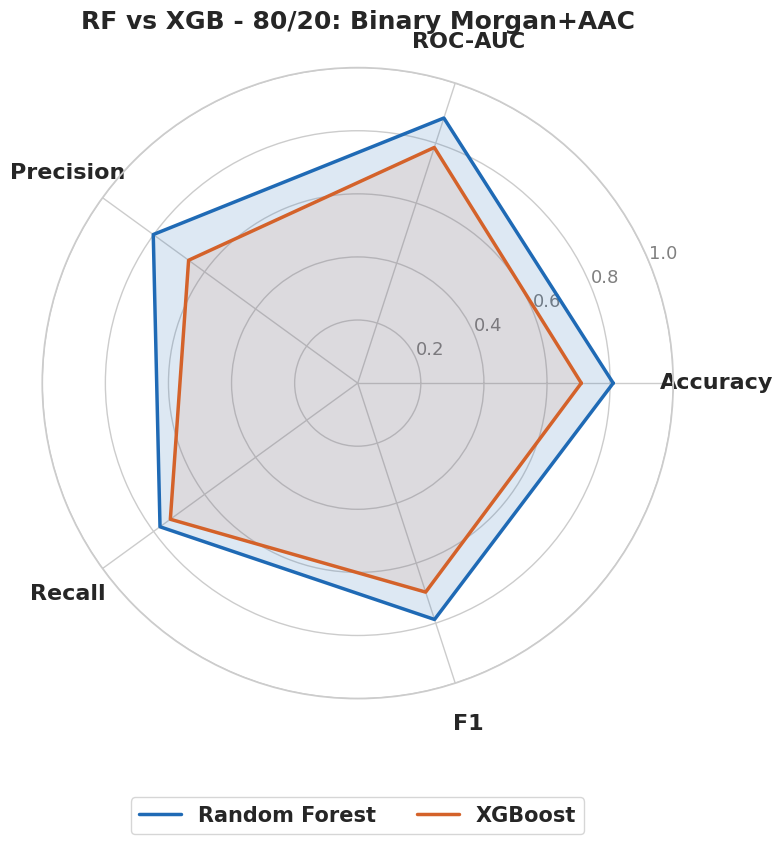

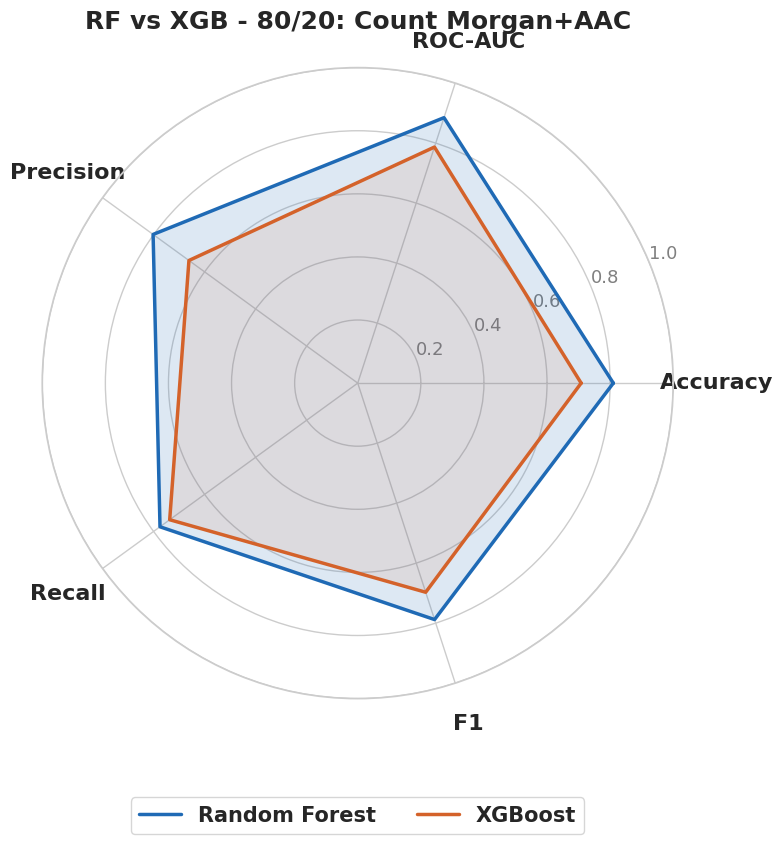

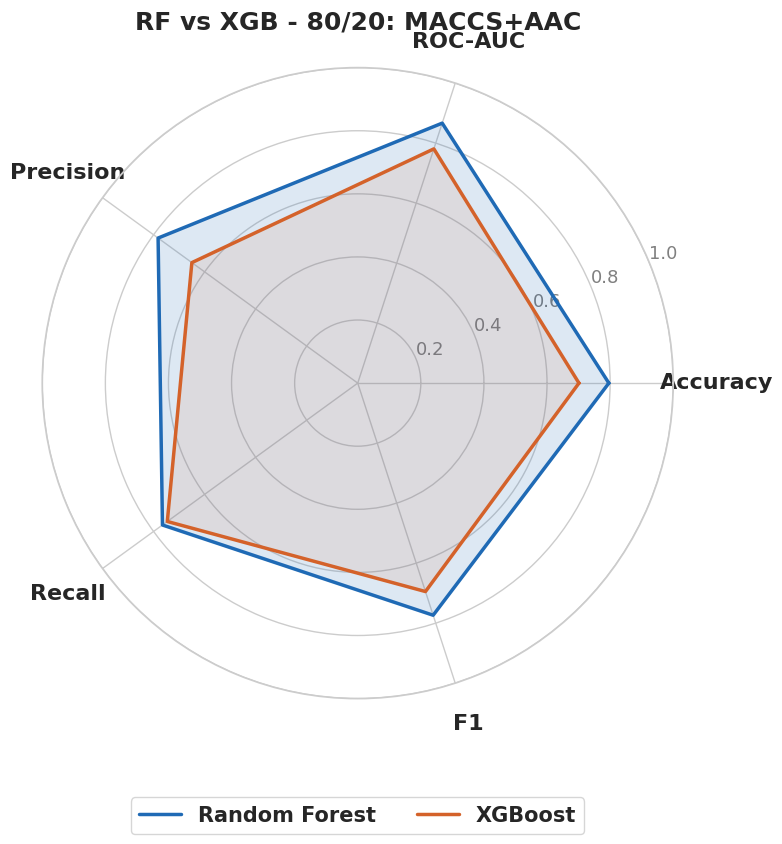

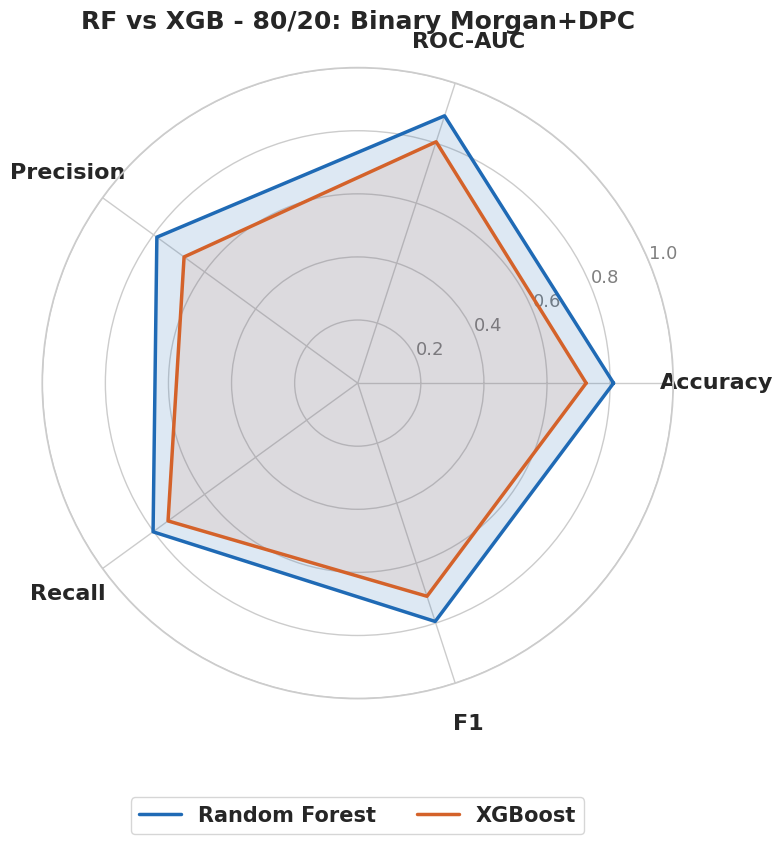

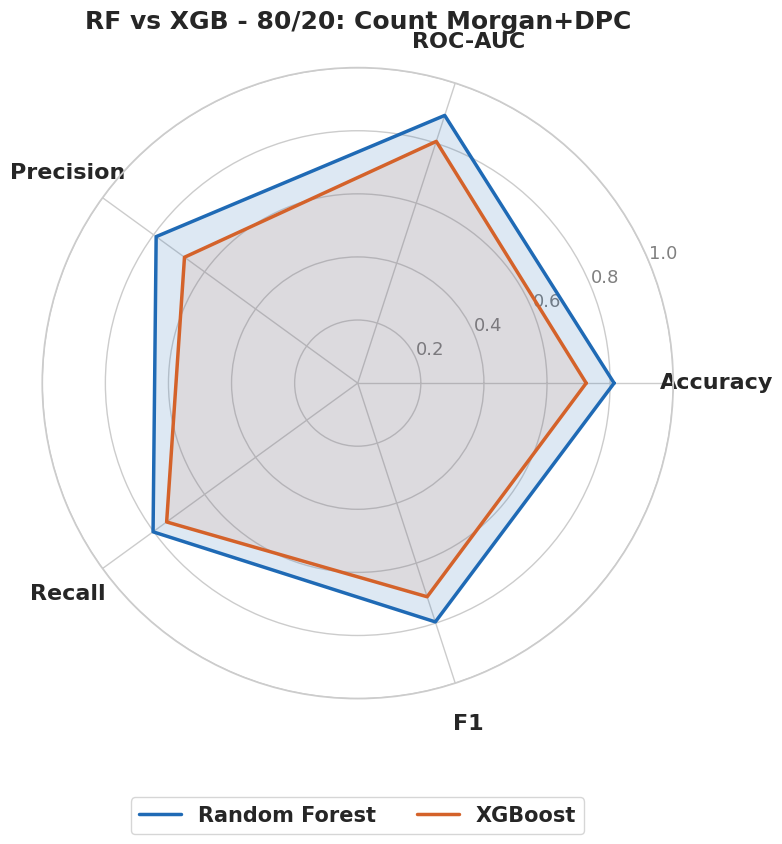

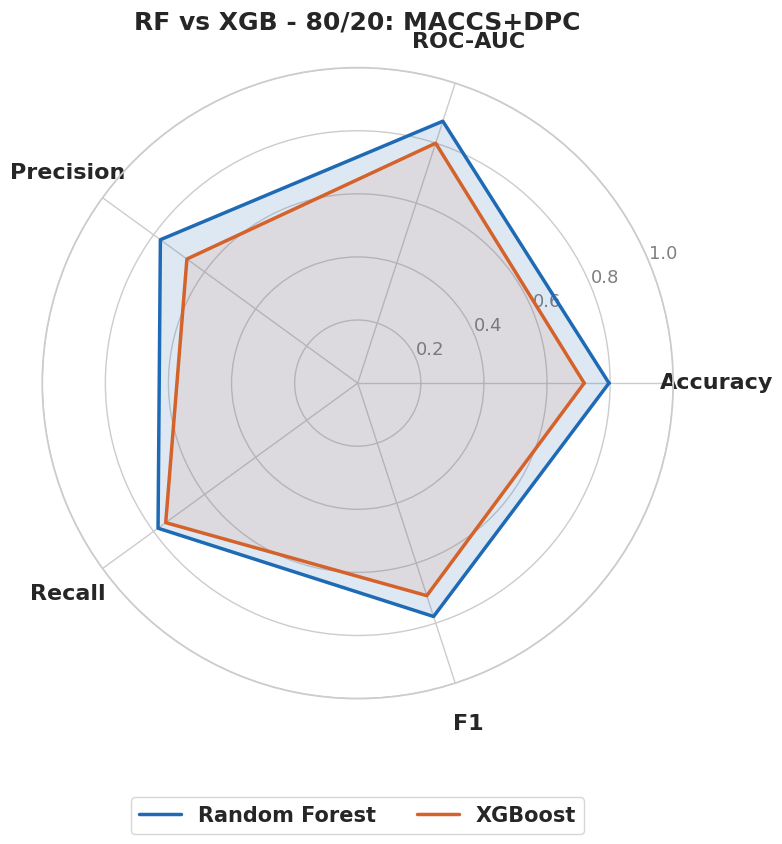

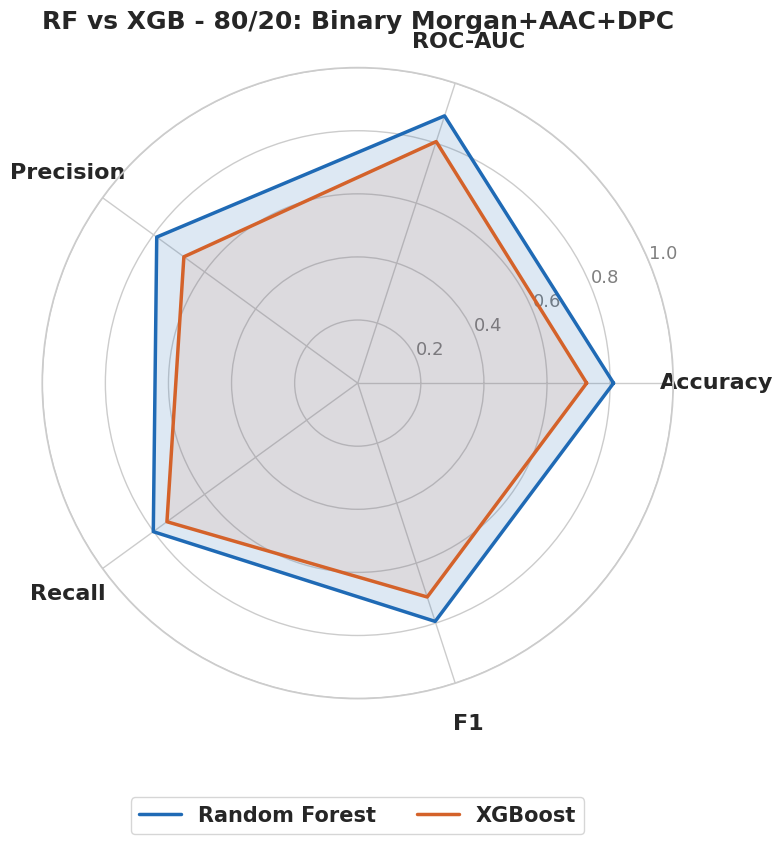

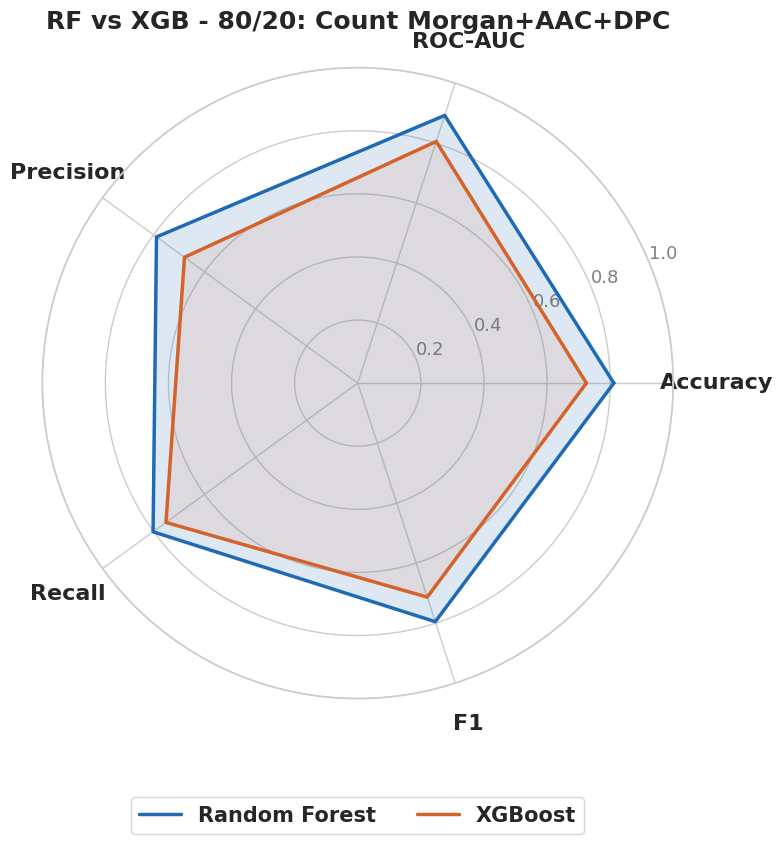

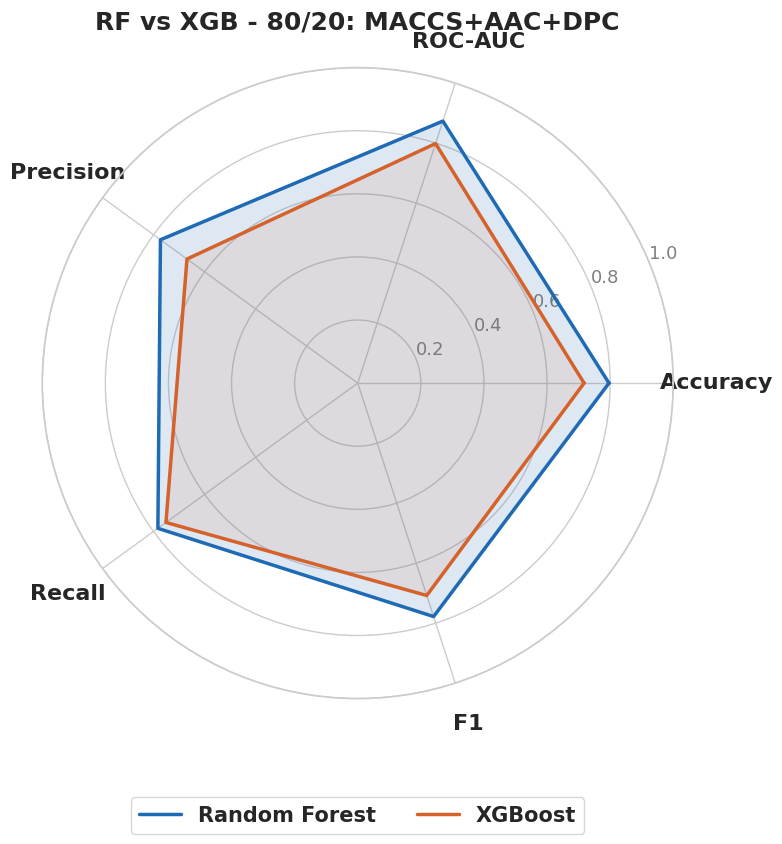

In [37]:
# STEP 0: Define metrics + angles
# RF_ROC_AUC
metrics = [m.replace("_", "-") for m in metrics]
num_metrics = len(metrics)

angles = np.linspace(0, 2 * np.pi, num_metrics, endpoint=False).tolist()
angles += angles[:1]

# ─────────────────────────────────────────────────────────────
# STEP 1: LOOP THROUGH REPRESENTATIONS
# ─────────────────────────────────────────────────────────────

for i in range(len(results_df)):

    row = results_df.iloc[i]
    rep = row["Representation"]

    rf_vals  = [row[f"RF_{m}"]  for m in metrics]
    xgb_vals = [row[f"XGB_{m}"] for m in metrics]

    rf_vals  += rf_vals[:1]
    xgb_vals += xgb_vals[:1]

    fig, ax = plt.subplots(figsize=(8, 9), subplot_kw=dict(polar=True))

    ax.plot(angles, rf_vals,  label="Random Forest", linewidth=2.5, color="#1f6ab5")
    ax.fill(angles, rf_vals,  alpha=0.15, color="#1f6ab5")

    ax.plot(angles, xgb_vals, label="XGBoost",       linewidth=2.5, color="#d4622a")
    ax.fill(angles, xgb_vals, alpha=0.10, color="#d4622a")

    ax.set_xticks(angles[:-1])

    ax.set_xticklabels(
        metrics,
        fontsize=16,
        fontweight="bold",
        fontfamily="DejaVu Sans",
    )

    ax.tick_params(axis="x", pad=18)

    ax.set_ylim(0, 1)

    ax.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
    ax.set_yticklabels(
        ["0.2", "0.4", "0.6", "0.8", "1.0"],
        fontsize=13,
        fontfamily="DejaVu Sans",
        color="gray",
    )

    ax.set_title(
        f"RF vs XGB - {split_label}: {rep}",
        pad=28,
        fontsize=18,
        fontweight="bold",
        fontfamily="DejaVu Sans",
    )

    ax.legend(
        loc="upper center",
        bbox_to_anchor=(0.5, -0.14),
        ncol=2,
        fontsize=15,
        frameon=True,
        prop={"family": "DejaVu Sans", "size": 15, "weight": "bold"},
    )

    plt.tight_layout()
    plt.show()

#####all 9 representations overlaid for each model

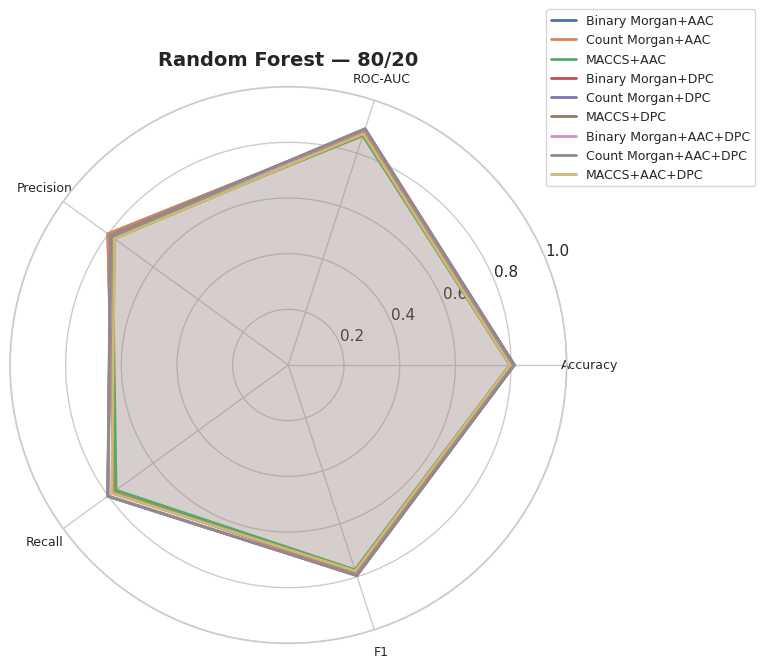

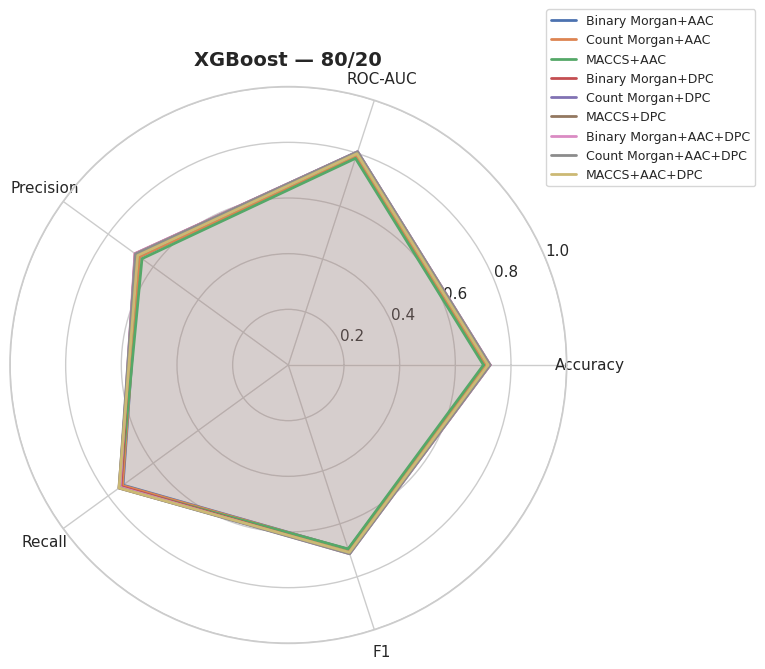

In [38]:
# STEP 0: Define metrics + angles
num_metrics = len(metrics)

angles = np.linspace(0, 2 * np.pi, num_metrics, endpoint=False).tolist()
angles += angles[:1]

# ─────────────────────────────────────────────────────────────
# FIGURE 1 — RF: all 9 representations overlaid
# ─────────────────────────────────────────────────────────────

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

for i in range(len(results_df)):
    row = results_df.iloc[i]
    rep = row["Representation"]

    rf_vals = [row[f"RF_{m}"] for m in metrics]
    rf_vals += rf_vals[:1]

    ax.plot(angles, rf_vals, linewidth=2, label=rep)
    ax.fill(angles, rf_vals, alpha=0.05)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(metrics, fontsize=9)
ax.set_ylim(0, 1)
ax.legend(loc="upper right", bbox_to_anchor=(1.35, 1.15), fontsize=9)
ax.set_title(f"Random Forest — {split_label}", fontsize=14, fontweight="bold", pad=15)

plt.tight_layout()
plt.show()

# ─────────────────────────────────────────────────────────────
# FIGURE 2 — XGB: all 9 representations overlaid
# ─────────────────────────────────────────────────────────────

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

for i in range(len(results_df)):
    row = results_df.iloc[i]
    rep = row["Representation"]

    xgb_vals = [row[f"XGB_{m}"] for m in metrics]
    xgb_vals += xgb_vals[:1]

    ax.plot(angles, xgb_vals, linewidth=2, label=rep)
    ax.fill(angles, xgb_vals, alpha=0.05)

ax.set_xticks(angles[:-1])
ax.set_xticklabels([f"{m}\n(inverted)" if m == "RMSE" else m for m in metrics])
ax.set_ylim(0, 1)
ax.legend(loc="upper right", bbox_to_anchor=(1.35, 1.15), fontsize=9)
ax.set_title(f"XGBoost — {split_label}", fontsize=14, fontweight="bold", pad=15)

plt.tight_layout()
plt.show()

##### Random Forest Performance Across Fingerprint Representations

In [39]:
# ─────────────────────────────────────────────────────────────
# NORMALIZATION FUNCTION FOR RADAR CHART
# ─────────────────────────────────────────────────────────────

def normalize_values(model_name, metrics, results_dict):
    """
    Extract metric values from rf_results dictionary
    for radar chart plotting.
    """

    values = []

    for metric in metrics:
        values.append(results_dict[model_name][metric])

    return values

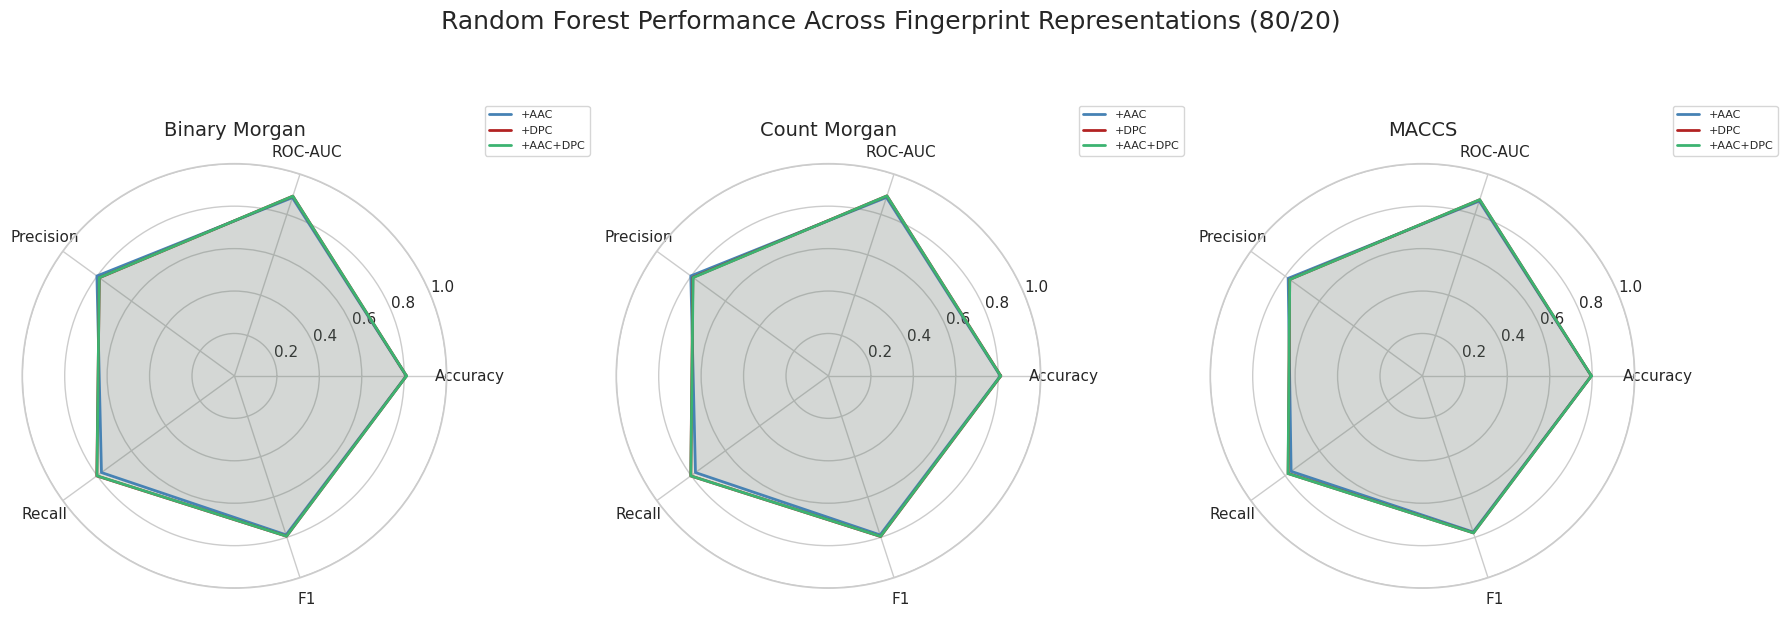

In [40]:
# ─────────────────────────────────────────────────────────────
# STEP 1: METRICS TO PLOT
# ─────────────────────────────────────────────────────────────

# metrics = ['Accuracy', 'ROC-AUC', 'Precision', 'Recall', 'F1', ]

# ─────────────────────────────────────────────────────────────
# STEP 2: RADAR SETUP
# ─────────────────────────────────────────────────────────────

num_metrics = len(metrics)

angles = np.linspace(0, 2 * np.pi, num_metrics, endpoint=False).tolist()
angles += angles[:1]

# ─────────────────────────────────────────────────────────────
# STEP 3: DEFINE FINGERPRINT GROUPS
# ─────────────────────────────────────────────────────────────

fingerprint_groups = {
    'Binary Morgan': [
        f'Random Forest - Binary Morgan+AAC ({split_label})',
        f'Random Forest - Binary Morgan+DPC ({split_label})',
        f'Random Forest - Binary Morgan+AAC+DPC ({split_label})',
    ],
    'Count Morgan': [
        f'Random Forest - Count Morgan+AAC ({split_label})',
        f'Random Forest - Count Morgan+DPC ({split_label})',
        f'Random Forest - Count Morgan+AAC+DPC ({split_label})',
    ],
    'MACCS': [
        f'Random Forest - MACCS+AAC ({split_label})',
        f'Random Forest - MACCS+DPC ({split_label})',
        f'Random Forest - MACCS+AAC+DPC ({split_label})',
    ]
}

# ─────────────────────────────────────────────────────────────
# STEP 4: COLORS
# ─────────────────────────────────────────────────────────────

rep_colors = {
    'AAC':     'steelblue',
    'DPC':     'firebrick',
    'AAC+DPC': 'mediumseagreen'
}

# ─────────────────────────────────────────────────────────────
# STEP 5: CREATE 3 RADAR CHARTS
# ─────────────────────────────────────────────────────────────

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 6),
    subplot_kw=dict(polar=True)
)

axes = axes.flatten()

# ─────────────────────────────────────────────────────────────
# STEP 6: LOOP THROUGH FINGERPRINT GROUPS
# ─────────────────────────────────────────────────────────────

for ax, (fingerprint, reps) in zip(axes, fingerprint_groups.items()):

    for rep in reps:

        # pull values directly from the results dictionary
        values = normalize_values(rep, metrics, rf_results)

        # close radar loop
        values += values[:1]

        # determine protein representation color
        if 'AAC+DPC' in rep:
            color = rep_colors['AAC+DPC']
        elif 'DPC' in rep:
            color = rep_colors['DPC']
        else:
            color = rep_colors['AAC']

        # legend label: show only the feature combo (e.g. "+AAC")
        short_label = rep.split(' - ')[1].split(' (')[0]   # e.g. "Binary Morgan+AAC"
        feature_label = '+' + short_label.split('+', 1)[1] # e.g. "+AAC"

        # plot
        ax.plot(
            angles,
            values,
            linewidth=2,
            label=feature_label,
            color=color
        )

        ax.fill(
            angles,
            values,
            alpha=0.10,
            color=color
        )

    # ─────────────────────────────────────────────────────────
    # FORMAT EACH SUBPLOT
    # ─────────────────────────────────────────────────────────

    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(metrics)

    ax.set_ylim(0, 1)

    ax.set_title(fingerprint, size=14, pad=20)

    ax.legend(
        loc='upper right',
        bbox_to_anchor=(1.35, 1.15),
        fontsize=8
    )

# ─────────────────────────────────────────────────────────────
# STEP 7: FINAL LAYOUT
# ─────────────────────────────────────────────────────────────

plt.suptitle(
    f"Random Forest Performance Across Fingerprint Representations ({split_label})",
    fontsize=18,
    y=1.05
)

plt.tight_layout()
plt.show()

####Random Forest Performance Across Protein Representations

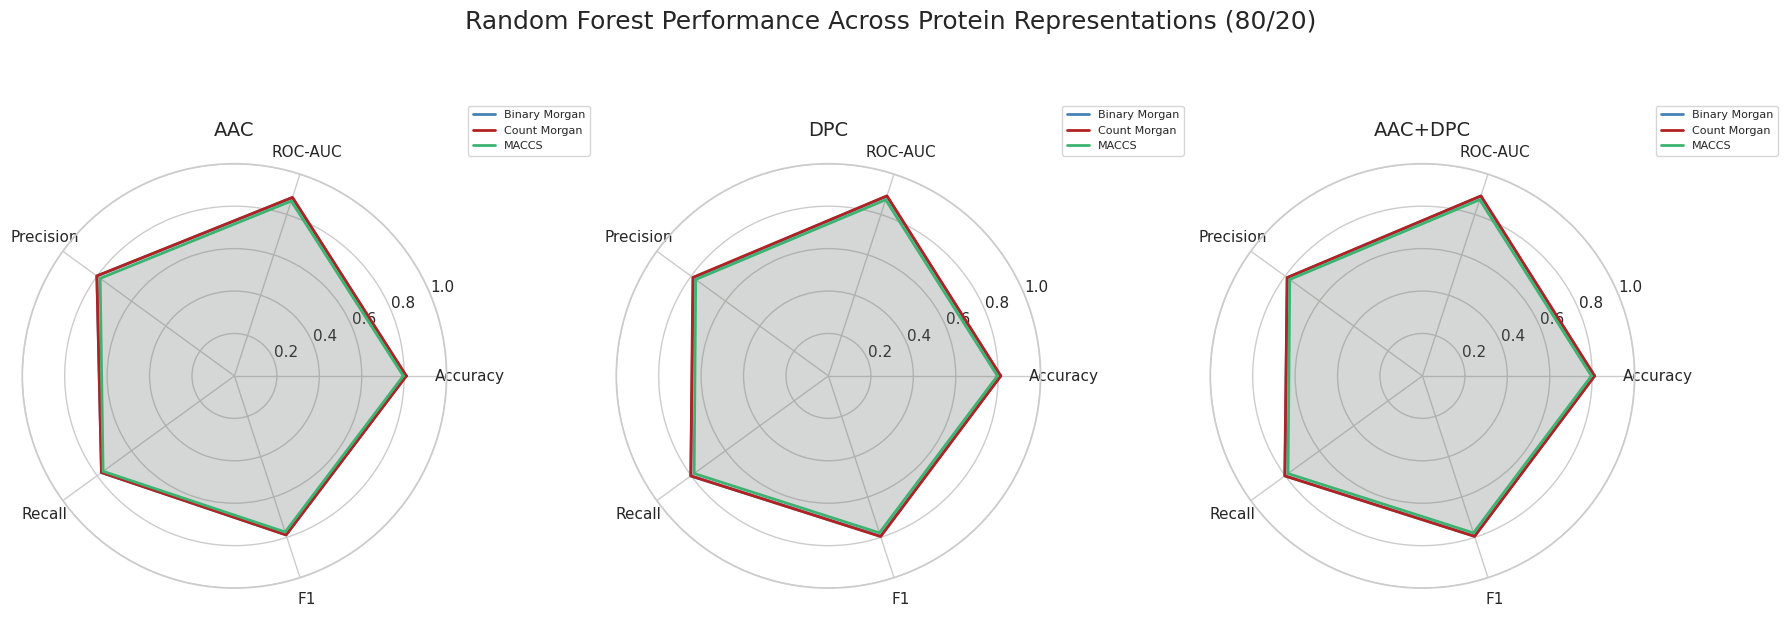

In [41]:
# ─────────────────────────────────────────────────────────────
# STEP 2: RADAR SETUP
# ─────────────────────────────────────────────────────────────

num_metrics = len(metrics)

angles = np.linspace(0, 2 * np.pi, num_metrics, endpoint=False).tolist()
angles += angles[:1]

# ─────────────────────────────────────────────────────────────
# STEP 3: DEFINE PROTEIN REPRESENTATION GROUPS
# ─────────────────────────────────────────────────────────────

protein_groups = {
    'AAC': [
        f'Random Forest - Binary Morgan+AAC ({split_label})',
        f'Random Forest - Count Morgan+AAC ({split_label})',
        f'Random Forest - MACCS+AAC ({split_label})',
    ],
    'DPC': [
        f'Random Forest - Binary Morgan+DPC ({split_label})',
        f'Random Forest - Count Morgan+DPC ({split_label})',
        f'Random Forest - MACCS+DPC ({split_label})',
    ],
    'AAC+DPC': [
        f'Random Forest - Binary Morgan+AAC+DPC ({split_label})',
        f'Random Forest - Count Morgan+AAC+DPC ({split_label})',
        f'Random Forest - MACCS+AAC+DPC ({split_label})',
    ]
}

# ─────────────────────────────────────────────────────────────
# STEP 4: COLORS FOR FINGERPRINT TYPES
# ─────────────────────────────────────────────────────────────

fingerprint_colors = {
    'Binary Morgan': 'steelblue',
    'Count Morgan':  'firebrick',
    'MACCS':         'mediumseagreen'
}

# ─────────────────────────────────────────────────────────────
# STEP 5: CREATE 3 RADAR CHARTS
# ─────────────────────────────────────────────────────────────

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 6),
    subplot_kw=dict(polar=True)
)

axes = axes.flatten()

# ─────────────────────────────────────────────────────────────
# STEP 6: LOOP THROUGH PROTEIN GROUPS
# ─────────────────────────────────────────────────────────────

for ax, (protein_rep, reps) in zip(axes, protein_groups.items()):

    for rep in reps:

            values = normalize_values(rep, metrics, rf_results)
            values += values[:1]

            # determine fingerprint color and label
            if 'Binary Morgan' in rep:
                color = fingerprint_colors['Binary Morgan']
                short_label = 'Binary Morgan'
            elif 'Count Morgan' in rep:
                color = fingerprint_colors['Count Morgan']
                short_label = 'Count Morgan'
            else:
                color = fingerprint_colors['MACCS']
                short_label = 'MACCS'
            # Plot
            ax.plot(angles, values, linewidth=2, label=short_label, color=color)
            ax.fill(angles, values, alpha=0.10, color=color)
    # ─────────────────────────────────────────────────────────
    # FORMAT EACH SUBPLOT
    # ─────────────────────────────────────────────────────────

    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(metrics)

    ax.set_ylim(0, 1)
    #ax.set_ylim(0.70, 0.95)
    #ax.set_yticks([0.70, 0.75, 0.80, 0.85, 0.90, 0.95])
    #ax.set_yticklabels(['0.70', '0.75', '0.80', '0.85', '0.90', '0.95'], fontsize=7)

    ax.set_title(protein_rep, size=14, pad=20)

    ax.legend(
        loc='upper right',
        bbox_to_anchor=(1.35, 1.15),
        fontsize=8
    )

# ─────────────────────────────────────────────────────────────
# STEP 7: FINAL LAYOUT
# ─────────────────────────────────────────────────────────────

plt.suptitle(
    f"Random Forest Performance Across Protein Representations ({split_label})",
    fontsize=18,
    y=1.05
)

plt.tight_layout()
plt.show()